In [1]:
import numpy as np
import healpy as hp

import matplotlib
from matplotlib import pyplot as plt

from scipy import stats
import matplotlib.gridspec as gridspec
import astropy.cosmology.units as cu
import astropy.units as u
import site
site.addsitedir('/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts') 
import quaia
import sampler
import seaborn as sns
from matplotlib.colors import LogNorm
import matplotlib.patches as mpatches
import pyccl as ccl
from matplotlib.lines import Line2D
from matplotlib import cm
from scipy.optimize import minimize
from astropy.cosmology import Planck18
from dynesty import NestedSampler
from dynesty import plotting as dyplot
from dynesty import utils as dyfunc
from astropy.coordinates import SkyCoord
from scipy import linalg
from scipy.special import gamma
from dynesty.results import Results
import io
from PIL import Image
from scipy.special import j0
import mcfit
from astropy import constants
import time
import copy
from scipy import special
from healpy.newvisufunc import projview
from scipy.special import sici, exp1
import matplotlib.colors as mcolors
import pickle

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/mcfit/kernels.py:10: SyntaxWarning: invalid escape sequence '\l'
  """Real deriv is wrt :math:`t`, complex deriv is wrt :math:`\ln t`"""


In [2]:
matplotlib.rcParams['ytick.labelsize'] = 18
matplotlib.rcParams['xtick.labelsize'] = 18
matplotlib.rcParams['axes.labelsize'] = 22
matplotlib.rcParams['legend.fontsize'] = 18
matplotlib.rcParams['axes.titlesize'] = 20

# G20.5
## Define parameters

In [3]:
G_hi = 20.5

In [4]:
nthreads = 18

In [5]:
z_bins = np.array([0.0, 1.0, 2.0, 3.0, 4.6])
z_array = range(len(z_bins)-1)

In [6]:
cosmo_planck18 = ccl.Cosmology(
    Omega_c=Planck18.Odm0,
    Omega_b=Planck18.Ob0,
    h=Planck18.h,
    Neff=Planck18.Neff,
    T_CMB=Planck18.Tcmb0.value,
    m_nu=Planck18.m_nu,
    sigma8=0.8102,   # or pull from wherever your actual source specifies Planck18's sigma8
    n_s=0.9665        # same
)

In [7]:
Delta = 200
delta_c = 1.686

In [8]:
hmf = ccl.halos.MassFuncTinker10()

In [9]:
M_max = 16.8 #15

In [10]:
n_bins = 201

In [11]:
L_bins = np.array([-32.0, -27.0, -26.0, -25.0, -20.0])[:0:-1]
L_bins

array([-20., -25., -26., -27.])

In [12]:
b = 30

In [13]:
fac_rand = 25

In [14]:
cmap_theta = sns.color_palette("flare_r", n_colors = len(L_bins))
cmap_theta

[(0.47936222, 0.18006056, 0.43733022),
 (0.66635279, 0.22717328, 0.43008427),
 (0.83765537, 0.30784814, 0.3723105),
 (0.90732341, 0.4939774, 0.38990532)]

In [15]:
mass_def = '200c'
hmf = ccl.halos.MassFuncTinker10(mass_def = mass_def) 

In [16]:
n_bins = 201

## Define functions

In [17]:
def M(bins, n_m, a = 1, cosmo = cosmo_planck18, mod = False, recenter = True, hmf = hmf, units = '(h/Mpc)^3'):

    n_g, nm = sampler.n_g_theory(bins, n_m, a = a, cosmo = cosmo, recenter = recenter, hmf = hmf, units = units)
    if recenter == True:
        n_g = np.trapz(n_g, quaia.recenter(bins))
        dm = np.diff(bins) 
        dn_dm = nm/(quaia.recenter(bins)*np.log(10))
    else:
        n_g = np.trapz(n_g, bins)
        dn_dm = nm/(bins*np.log(10))

    n_m[~np.isfinite(n_m)]=0 
    integrand = dn_dm*n_m
    integrand[np.isnan(integrand)]=0
    
    if recenter == True:
        return sampler.bias_function(n_g, integrand, quaia.recenter(bins), bins, recenter = recenter), n_g
    else:
        return sampler.bias_function(n_g, integrand, bins, bins, recenter = recenter), n_g

## Calculate number density as $n_q \approx \int_0^{\infty} d M \frac{d n}{d M}\langle N(M)\rangle$

In [18]:
LMC = SkyCoord(['05 23 34.6 -69 45 22'], unit=(u.hourangle, u.deg)) #https://simbad.u-strasbg.fr/simbad/sim-id?Ident=Large+Magellanic+Cloud

In [19]:
LMC_radius = 9*u.deg

In [20]:
SMC = SkyCoord(['00 52 38.0 -72 48 01'], unit=(u.hourangle, u.deg)) # https://simbad.u-strasbg.fr/simbad/sim-id?Ident=small+Magellanic+Cloud

In [21]:
SMC_radius = 5*u.deg

In [22]:
NSIDE = 64

In [23]:
NPIX = hp.nside2npix(NSIDE)

In [24]:
theta, phi = hp.pix2ang(NSIDE, range(NPIX), lonlat=True)
c = SkyCoord(ra=theta*u.degree, dec=phi*u.degree)
LMC_idx, _, _, _ = SkyCoord.search_around_sky(LMC, c, LMC_radius)
SMC_idx, _, _, _ = SkyCoord.search_around_sky(SMC, c, SMC_radius)
MC_idx = np.append(LMC_idx,SMC_idx)
MC_mask = np.full_like(range(NPIX), True, dtype = bool)
MC_mask[MC_idx] = False

In [25]:
selfunc_mask = np.abs(c.galactic.b.value)>=b

In [26]:
dz = np.linspace(0, 4.6)

In [27]:
da = 1/(1+dz)

In [28]:
N_q, n_q = {L: [] for L in L_bins}, {L: [] for L in L_bins}
H0_c_dN_dz_norm = {L: [] for L in L_bins}
z_sigma = {L: [] for L in L_bins}
zbin = {L: [] for L in L_bins}

for i in range(len(L_bins)):
            
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, _, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_bins], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'max'], fac_rand = fac_rand, 
                                                                                          n_bins = [None, None], b = b, mask_type = 'b')
        N = len(tab_datahi_mask_zbin0)
        f_sky = 1/(4*np.pi)*np.sum(selfunc_hi_bin0[selfunc_mask & MC_mask]*hp.nside2pixarea(NSIDE))
        V = f_sky*(Planck18.comoving_volume(z_bins[j+1])-Planck18.comoving_volume(z_bins[j]))*Planck18.h**3/u.h**3
        N_q[L_bins[i]].append(N)
        n_q[L_bins[i]].append(N/V.value)

        dN_dz = np.sum(stats.norm.pdf(dz[None, :], loc=tab_datahi_mask_zbin0['redshift_quaia'][:, None], scale=tab_datahi_mask_zbin0['redshift_quaia_err'][:, None]), axis = 0)
        dN_dz /= np.sum(stats.norm.cdf(dz[-1], loc=tab_datahi_mask_zbin0['redshift_quaia'], scale=tab_datahi_mask_zbin0['redshift_quaia_err']))
        H0_c_dN_dz_norm[L_bins[i]].append(ccl.background.h_over_h0(
            cosmo_planck18, da)*Planck18.H0.to(1/u.s)/constants.c.to(u.Mpc/u.s)*dN_dz**2)

        z_sigma[L_bins[i]].append(np.percentile(tab_datahi_mask_zbin0['redshift_quaia'], [16, 84]))

        zbin[L_bins[i]].append(np.median(tab_datahi_mask_zbin0['redshift_quaia']))

Pixels masked by MC but not already by selfunc: 2468
G20.5_zmin0.0zmax1.0_Lmax-20.0: 0.33              218365 vs 324336
Pixels masked by MC but not already by selfunc: 4785
G20.5_zmin1.0zmax2.0_Lmax-20.0: 0.30              453228 vs 648196
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-20.0: 0.28              207602 vs 286508
Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-20.0: 0.23              28043 vs 36458
Pixels masked by MC but not already by selfunc: 490
G20.5_zmin0.0zmax1.0_Lmax-25.0: 0.46              29985 vs 55261
Pixels masked by MC but not already by selfunc: 3840
G20.5_zmin1.0zmax2.0_Lmax-25.0: 0.33              336125 vs 502242
Pixels masked by MC but not already by selfunc: 2764
G20.5_zmin2.0zmax3.0_Lmax-25.0: 0.28              207602 vs 286508
Pixels masked by MC but not already by selfunc: 307
G20.5_zmin3.0zmax4.6_Lmax-25.0: 0.23              28043 vs 36458
Pixels masked by MC but not already by selfunc: 1

## Limit angular scales to $0.001^\circ\geq \theta \geq 10^\circ$

In [29]:
# Create the bins array
rmin = 0.001
rmax = 10.0
nbins = 30 #20 #30 #20
thetabins = np.logspace(np.log10(rmin), np.log10(rmax), nbins+1)
np.log10(thetabins), quaia.recenter(np.log10(thetabins)), np.diff(np.log10(thetabins))

(array([-3.        , -2.86666667, -2.73333333, -2.6       , -2.46666667,
        -2.33333333, -2.2       , -2.06666667, -1.93333333, -1.8       ,
        -1.66666667, -1.53333333, -1.4       , -1.26666667, -1.13333333,
        -1.        , -0.86666667, -0.73333333, -0.6       , -0.46666667,
        -0.33333333, -0.2       , -0.06666667,  0.06666667,  0.2       ,
         0.33333333,  0.46666667,  0.6       ,  0.73333333,  0.86666667,
         1.        ]),
 array([-2.93333333e+00, -2.80000000e+00, -2.66666667e+00, -2.53333333e+00,
        -2.40000000e+00, -2.26666667e+00, -2.13333333e+00, -2.00000000e+00,
        -1.86666667e+00, -1.73333333e+00, -1.60000000e+00, -1.46666667e+00,
        -1.33333333e+00, -1.20000000e+00, -1.06666667e+00, -9.33333333e-01,
        -8.00000000e-01, -6.66666667e-01, -5.33333333e-01, -4.00000000e-01,
        -2.66666667e-01, -1.33333333e-01, -2.35922393e-16,  1.33333333e-01,
         2.66666667e-01,  4.00000000e-01,  5.33333333e-01,  6.66666667e-01,
       

## Pick cosmology

In [30]:
cosmo = 'Planck'

In [31]:
N_jk = 50 #20 #65 #50 #30 #15 #80

In [32]:
L_array = np.array([-32.0, -27.0, -26.0, -25.0, -20.0])[::-1]

In [33]:
delta_xlim = np.diff(np.log10(thetabins))[0]/2
delta_xlim/2, thetabins, 10**(np.log10(thetabins) - 2*delta_xlim)

(0.033333333333333326,
 array([1.00000000e-03, 1.35935639e-03, 1.84784980e-03, 2.51188643e-03,
        3.41454887e-03, 4.64158883e-03, 6.30957344e-03, 8.57695899e-03,
        1.16591440e-02, 1.58489319e-02, 2.15443469e-02, 2.92864456e-02,
        3.98107171e-02, 5.41169527e-02, 7.35642254e-02, 1.00000000e-01,
        1.35935639e-01, 1.84784980e-01, 2.51188643e-01, 3.41454887e-01,
        4.64158883e-01, 6.30957344e-01, 8.57695899e-01, 1.16591440e+00,
        1.58489319e+00, 2.15443469e+00, 2.92864456e+00, 3.98107171e+00,
        5.41169527e+00, 7.35642254e+00, 1.00000000e+01]),
 array([7.35642254e-04, 1.00000000e-03, 1.35935639e-03, 1.84784980e-03,
        2.51188643e-03, 3.41454887e-03, 4.64158883e-03, 6.30957344e-03,
        8.57695899e-03, 1.16591440e-02, 1.58489319e-02, 2.15443469e-02,
        2.92864456e-02, 3.98107171e-02, 5.41169527e-02, 7.35642254e-02,
        1.00000000e-01, 1.35935639e-01, 1.84784980e-01, 2.51188643e-01,
        3.41454887e-01, 4.64158883e-01, 6.30957344e-01,

In [34]:
N_q_cut = {L: [] for L in L_bins}

for i in range(len(L_bins)):
            
    for j in z_array:
        
        tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, selfunc_hi_bin0, _, _ = quaia.make_bins(G_hi, [j, i], True, ['z', 'L'], 
                                                                                         bins = [z_bins, L_array[::-1]], tab_gcat_type = 'data', 
                                                                                          method = ['minmax', 'minmax'], fac_rand = fac_rand, 
                                                                                          n_bins = [None, None], b = b, mask_type = 'b')
        N = len(tab_datahi_mask_zbin0)
        N_q_cut[L_bins[i]].append(N)

Pixels masked by MC but not already by selfunc: 35
G20.5_zmin0.0zmax1.0_Lmin-32.0Lmax-27.0: 0.59              754 vs 1860
Pixels masked by MC but not already by selfunc: 365
G20.5_zmin1.0zmax2.0_Lmin-32.0Lmax-27.0: 0.46              20349 vs 38015
Pixels masked by MC but not already by selfunc: 1035
G20.5_zmin2.0zmax3.0_Lmin-32.0Lmax-27.0: 0.37              64134 vs 102196
Pixels masked by MC but not already by selfunc: 256
G20.5_zmin3.0zmax4.6_Lmin-32.0Lmax-27.0: 0.26              21337 vs 28856
Pixels masked by MC but not already by selfunc: 88
G20.5_zmin0.0zmax1.0_Lmin-27.0Lmax-26.0: 0.50              5182 vs 10412
Pixels masked by MC but not already by selfunc: 1173
G20.5_zmin1.0zmax2.0_Lmin-27.0Lmax-26.0: 0.39              88880 vs 144714
Pixels masked by MC but not already by selfunc: 1522
G20.5_zmin2.0zmax3.0_Lmin-27.0Lmax-26.0: 0.24              119349 vs 156795
Pixels masked by MC but not already by selfunc: 49
G20.5_zmin3.0zmax4.6_Lmin-27.0Lmax-26.0: 0.12              6706 vs

<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:34: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:34: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_129223/2814806904.py:29: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma[::2], markeredgewidth = 2.5, linestyle = 'none', label = '${}<M_i\leq{}$'.format(L_array[::-1][i], L_array[::-1][i+1])) #capsize = 2.5
/tmp/ipykernel_129223/2814806904.py:34: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


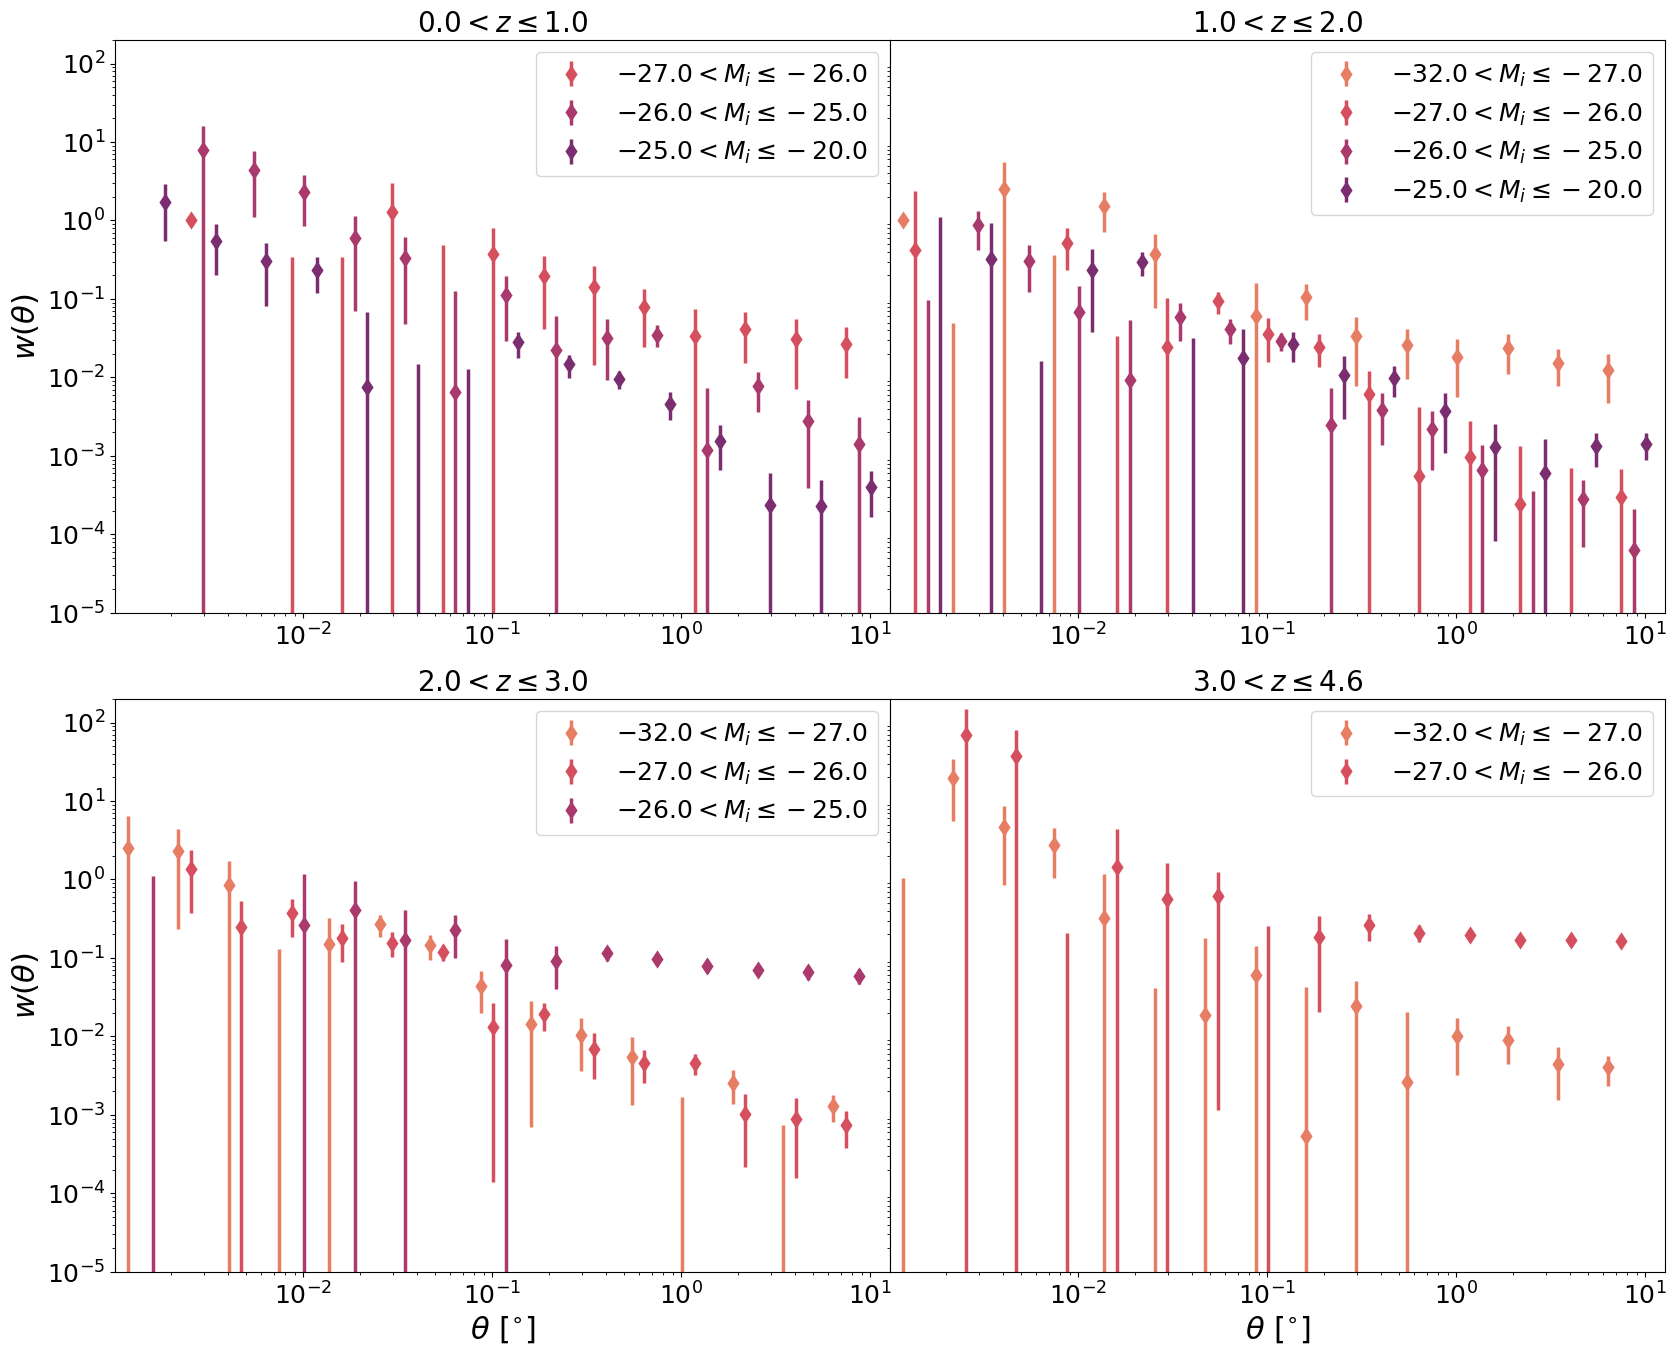

In [35]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if np.round(N_q_cut[L_bins[i]][j]/1000)>1:

            # i = 3
            # j = 0
            try:
                sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], N_jk, cosmo, b))))
            except Exception as e:
                print(e)
                sigma = 0
            try:
                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b))

                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b)))            
            
                ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)[::2]) + i*delta_xlim/2*2), wp_zbin_i[::2], linewidth = 2.5, marker = 'd', color = cmap_theta[::-1][i],
                            yerr = sigma[::2], markeredgewidth = 2.5, linestyle = 'none', label = '${}<M_i\leq{}$'.format(L_array[::-1][i], L_array[::-1][i+1])) #capsize = 2.5
                
            except Exception as e:
                print(e)

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-5, 2e2)
            
            if j%2==0:
                ax1.set_ylabel(r"$w(\theta)$")
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
            ax1.legend(loc = 'upper right')
            
plt.savefig('../figures/wtheta_LminLmax.pdf', bbox_inches = 'tight')
plt.show()

<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_129223/3802344075.py:27: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma[::2], markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5
/tmp/ipykernel_129223/3802344075.py:29: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))


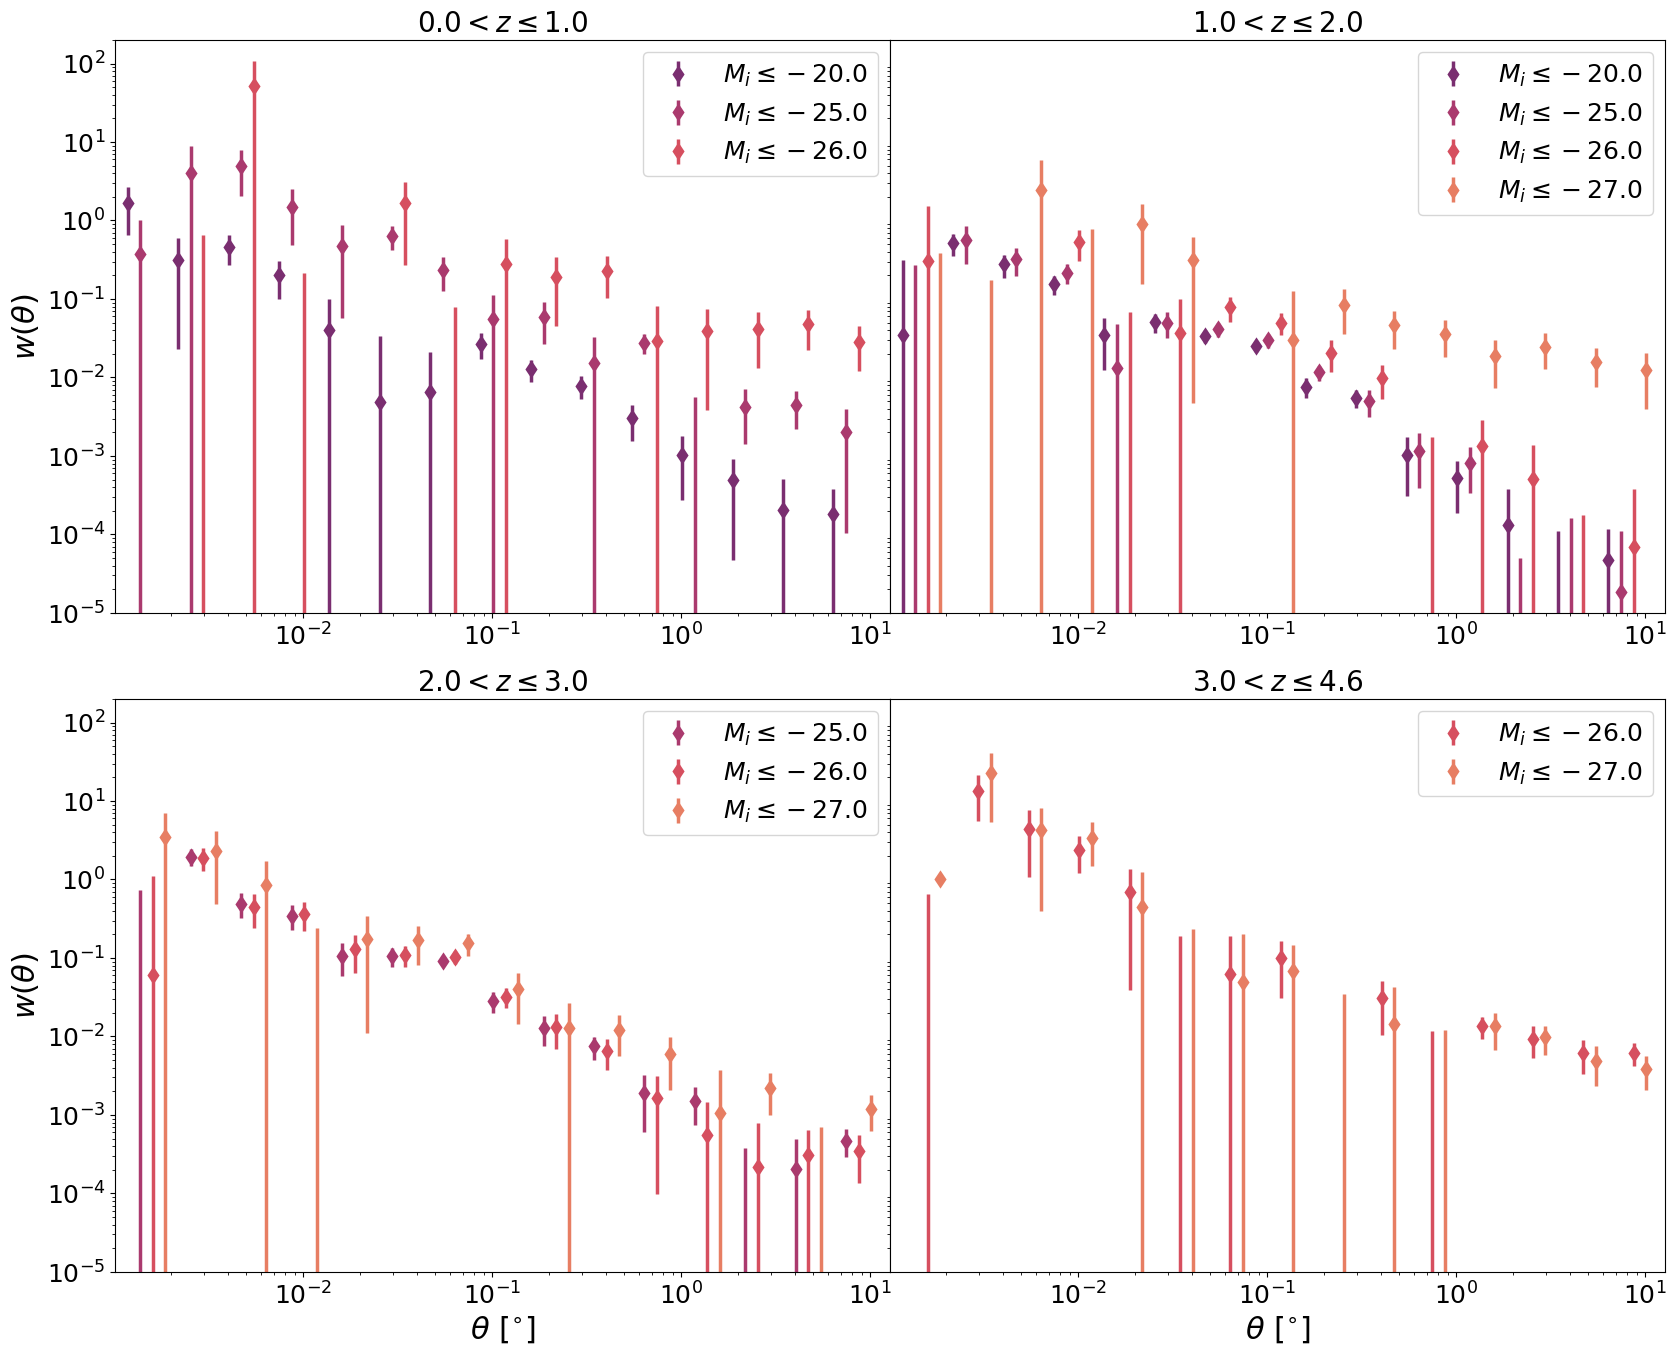

In [36]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            try:
                sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))))
            except:
                sigma = 0
            try:
                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            except:
                pass
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b)))            
            
            ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)[::2]) + i*delta_xlim/2*2), wp_zbin_i[::2], linewidth = 2.5, marker = 'd', color = cmap_theta[i],
                        yerr = sigma[::2], markeredgewidth = 2.5, linestyle = 'none', label = '$M_i\leq{}$'.format(L_bins[i])) #capsize = 2.5

            ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-5, 2e2)
            
            if j%2==0:
                ax1.set_ylabel(r"$w(\theta)$")
            else:
                ax1.set_yticks([])
            if j > 1:
                ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
            ax1.legend(loc = 'upper right')

plt.savefig('../figures/wtheta_Lmax.pdf', bbox_inches = 'tight')
plt.show()

<>:28: SyntaxWarning: invalid escape sequence '\l'
<>:30: SyntaxWarning: invalid escape sequence '\l'
<>:28: SyntaxWarning: invalid escape sequence '\l'
<>:30: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_129223/2602416685.py:28: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma[::2], markeredgewidth = 2.5, linestyle = 'None', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5
/tmp/ipykernel_129223/2602416685.py:30: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))


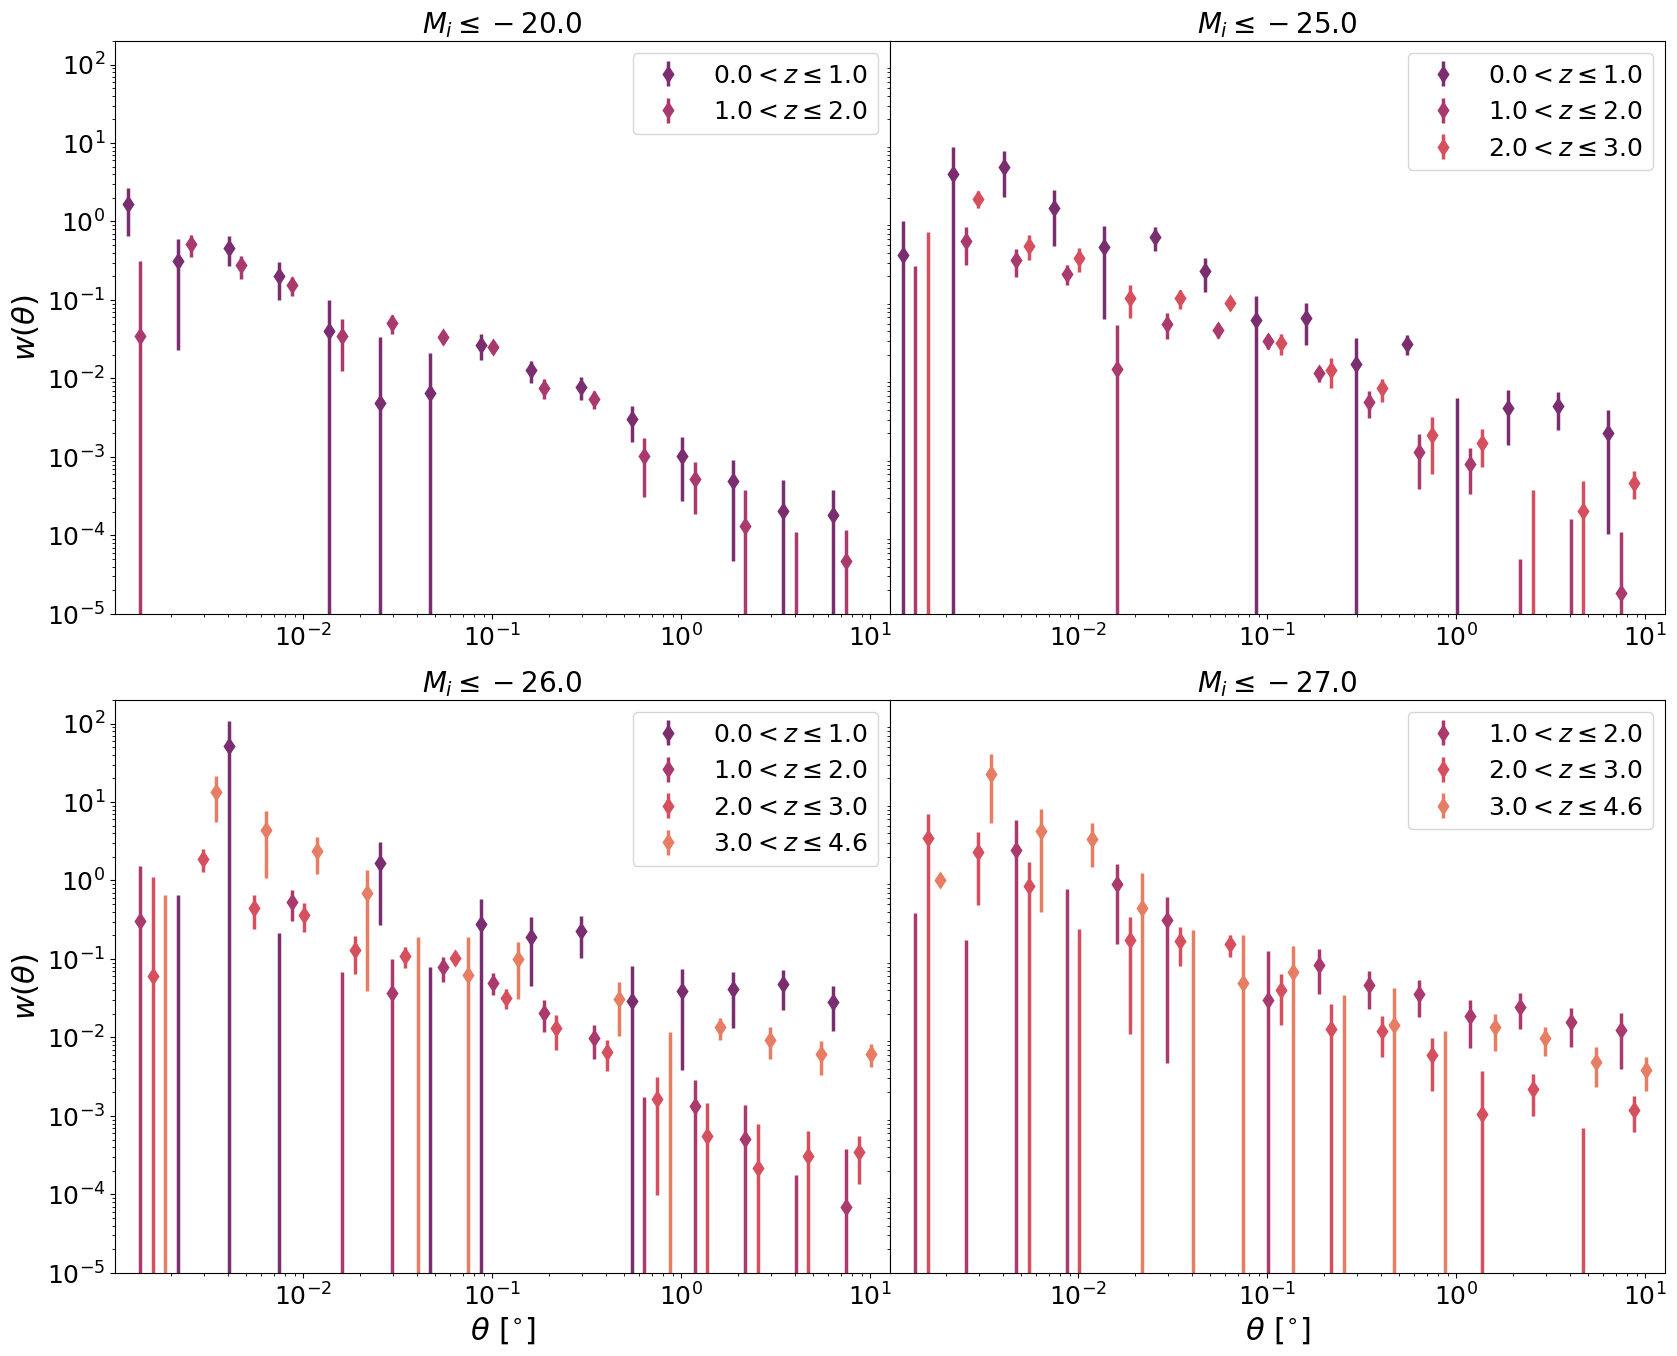

In [37]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for i in range(len(L_bins)):

    ax1 = fig.add_subplot(gs[i])
    
    for j in range(len(z_array)):
    

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            try:
                sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))))
            except:
                sigma = 0
            try:
                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            except:
                pass
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b)))            
            
            ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)[::2]) + j*delta_xlim/2*2), wp_zbin_i[::2], linewidth = 2.5, marker = 'd', color = cmap_theta[j],
                        yerr = sigma[::2], markeredgewidth = 2.5, linestyle = 'None', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5

            ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-5, 2e2)
            
            if i%2==0:
                ax1.set_ylabel(r"$w(\theta)$")
            else:
                ax1.set_yticks([])
            if i > 1:
                ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
            ax1.legend(loc = 'upper right')

plt.savefig('../figures/wtheta_Lmax_zbins.pdf', bbox_inches = 'tight')
plt.show()

In [38]:
bins_m = np.logspace(9, M_max, n_bins) #M_min_samples

<>:31: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\l'
<>:31: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_129223/3587256409.py:31: SyntaxWarning: invalid escape sequence '\l'
  ax1.plot(10**(np.log10(quaia.recenter(thetabins[::2])) + j*delta_xlim/2*2), b_q[::2], linewidth = 2.5, color = cmap_theta[j], markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
/tmp/ipykernel_129223/3587256409.py:33: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: invalid value encountered in divide
  return fdu

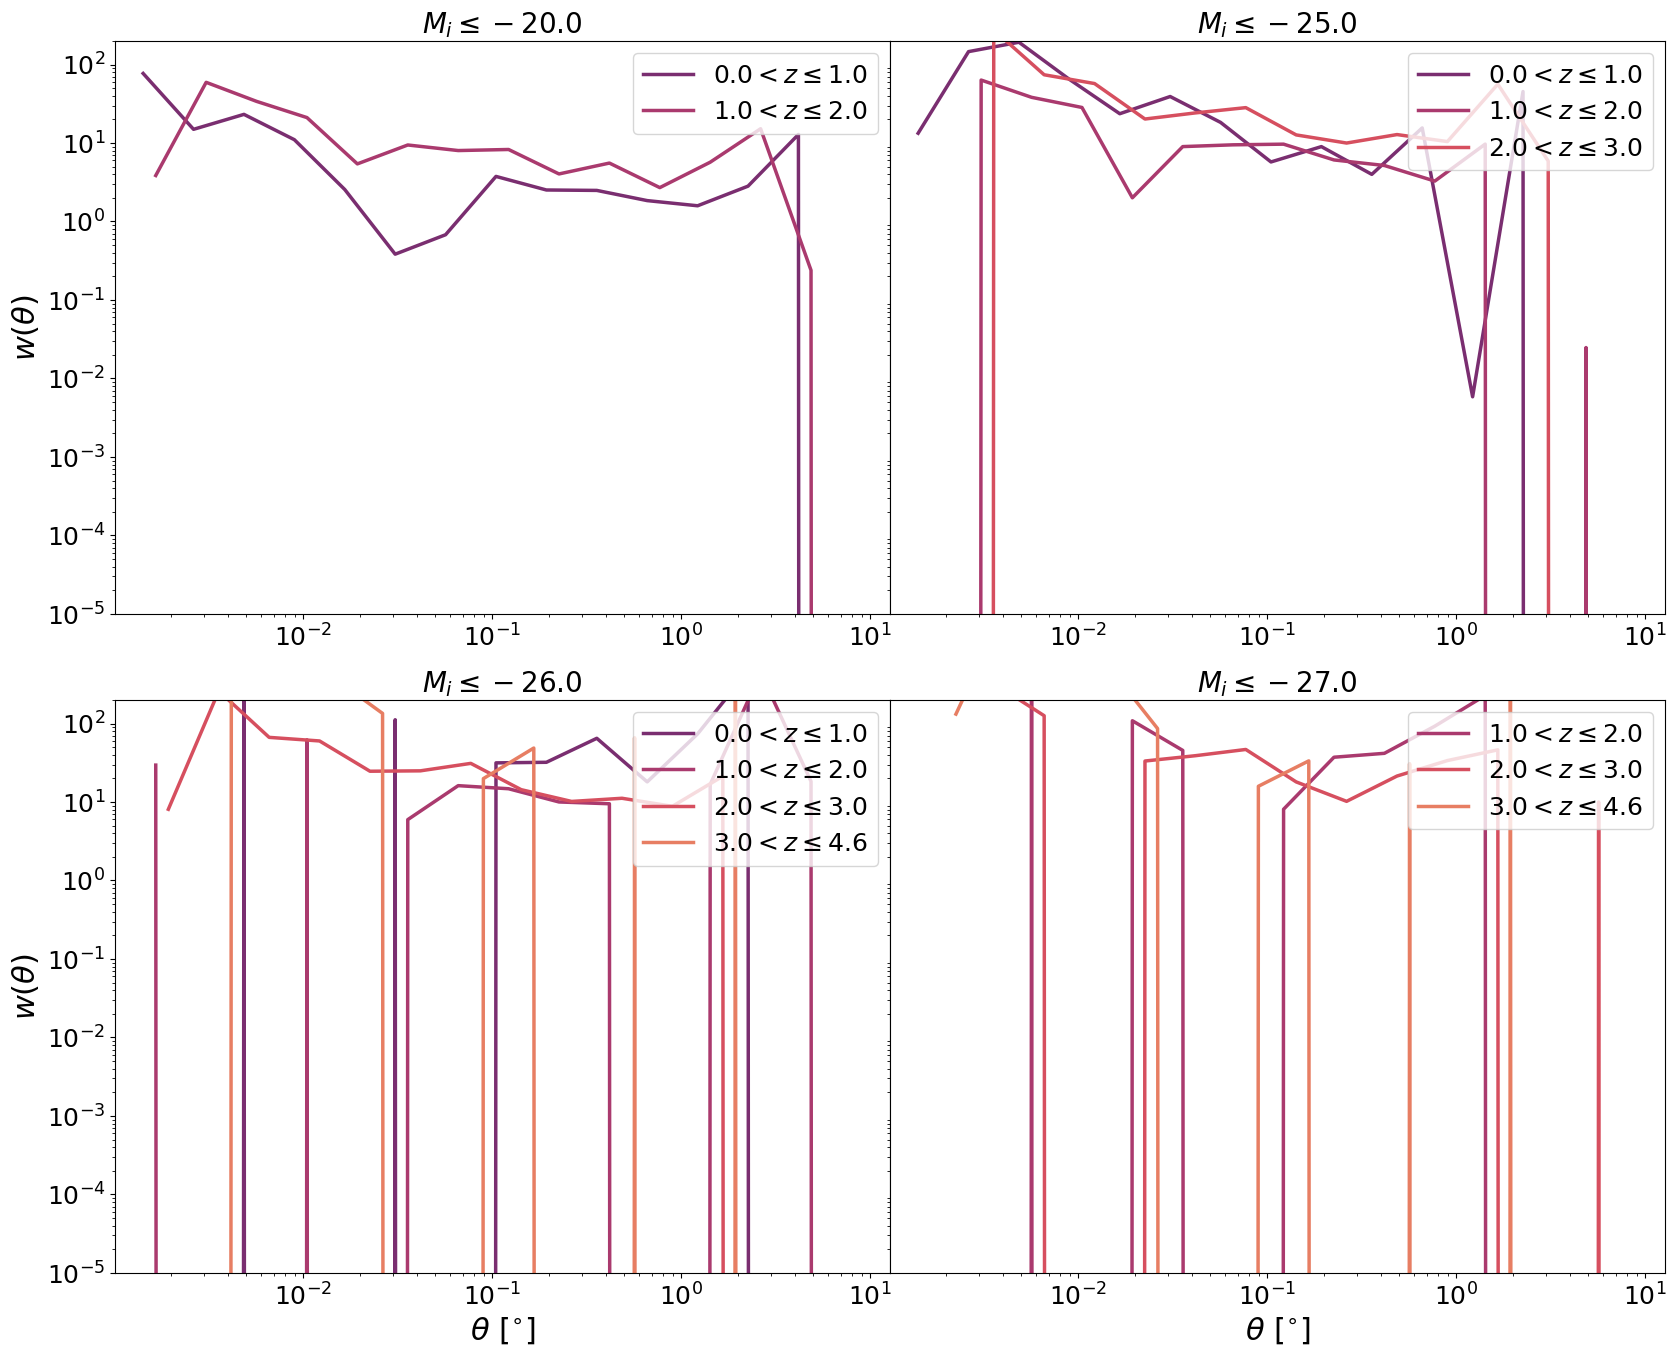

In [39]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
for i in range(len(L_bins)):

    ax1 = fig.add_subplot(gs[i])
    
    for j in range(len(z_array)):
    

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            try:
                sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))))
            except:
                sigma = 0
            try:
                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            except:
                pass
            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b)))            
            
            # ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)[::2]) + j*delta_xlim/2*2), wp_zbin_i[::2], linewidth = 2.5, marker = 'd', color = cmap_theta[j],
            #             yerr = sigma[::2], markeredgewidth = 2.5, linestyle = 'None', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5
            w_m = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [1, 9, 0, 12, 1.5], 2, one_halo = True, two_halo = True, b_z = 1)
            b_q = wp_zbin_i/w_m
            ax1.plot(10**(np.log10(quaia.recenter(thetabins[::2])) + j*delta_xlim/2*2), b_q[::2], linewidth = 2.5, color = cmap_theta[j], markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))

            ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
            ax1.set_yscale('log')
            ax1.set_xscale('log')
            ax1.set_ylim(1e-5, 2e2)
            
            if i%2==0:
                ax1.set_ylabel(r"$w(\theta)$")
            else:
                ax1.set_yticks([])
            if i > 1:
                ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
            ax1.legend(loc = 'upper right')

# plt.savefig('../figures/wtheta_Lmax_zbins.pdf', bbox_inches = 'tight')
plt.show()

<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_129223/3935193555.py:29: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma[::2], markeredgewidth = 2.5, linestyle = 'None', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5


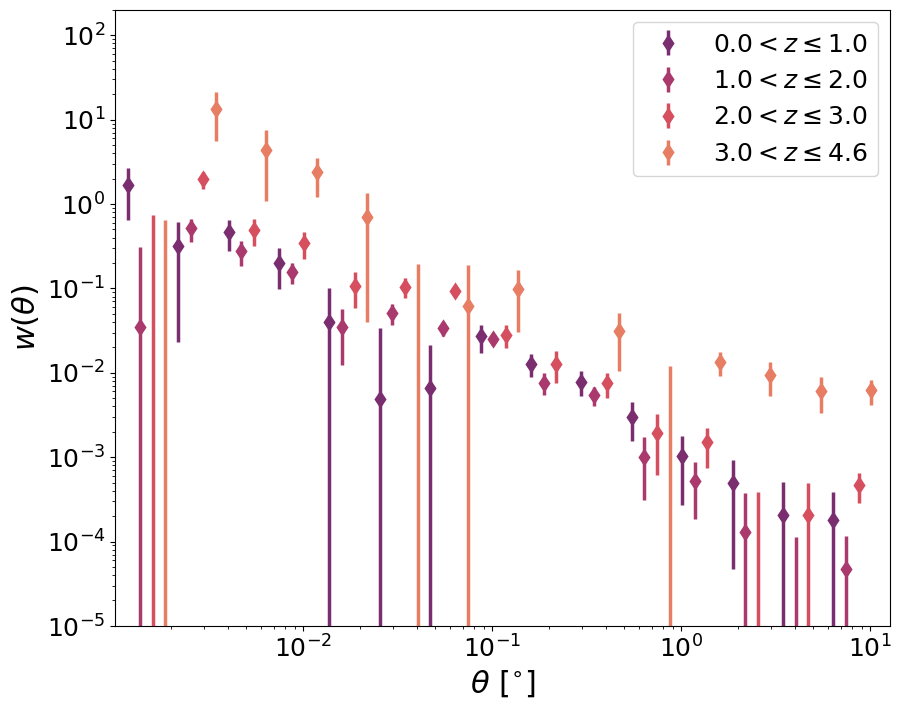

In [40]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
i = 0

ax1 = fig.add_subplot(gs[i])

for j in range(len(z_array)):

# for i in range(len(L_bins)):

# if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

    try:
        sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
            G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))))
    except:
        sigma = 0
    try:
        wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_{}_MC_b{}.npy'.format(
            G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
    except:
        pass
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b)))            
    
    ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)[::2]) + j*delta_xlim/2*2), wp_zbin_i[::2], linewidth = 2.5, marker = 'd', color = cmap_theta[j],
                yerr = sigma[::2], markeredgewidth = 2.5, linestyle = 'None', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5
    
    # ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
    ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
    ax1.set_yscale('log')
    ax1.set_xscale('log')
    ax1.set_ylim(1e-5, 2e2)
    
    # if j%2==0:
    ax1.set_ylabel(r"$w(\theta)$")
    # else:
    #     ax1.set_yticks([])
    # if j > 1:
    ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
    ax1.legend(loc = 'upper right')

# plt.savefig('../figures/wtheta_Lmax.pdf', bbox_inches = 'tight')
plt.show()

<>:33: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_129223/81761882.py:33: SyntaxWarning: invalid escape sequence '\l'
  label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/astropy/units/quantity.py:653: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


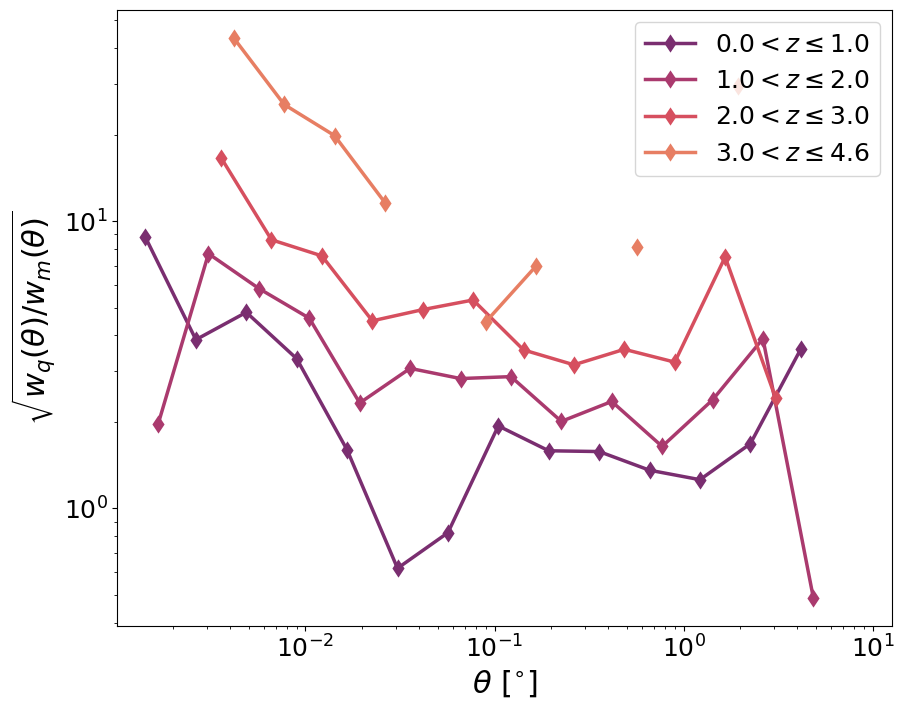

In [41]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
i = 0

ax1 = fig.add_subplot(gs[i])

for j in range(len(z_array)):

# for i in range(len(L_bins)):

# if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

    try:
        sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
            G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))))
    except:
        sigma = 0
    try:
        wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_{}_MC_b{}.npy'.format(
            G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
    except:
        pass
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b)))            
    
    # ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)[::2]) + j*delta_xlim/2*2), wp_zbin_i[::2], linewidth = 2.5, marker = 'd', color = cmap_theta[j],
    #             yerr = sigma[::2], markeredgewidth = 2.5, linestyle = 'None', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5
    w_m = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [1, 9, 0, 12, 1.5], 2, one_halo = True, two_halo = True, b_z = 1)
    b_q = np.sqrt(wp_zbin_i/w_m)
    ax1.plot(10**(np.log10(quaia.recenter(thetabins[::2])) + j*delta_xlim/2*2), b_q[::2], linewidth = 2.5, color = cmap_theta[j], markeredgewidth = 2.5, linestyle = '-', marker = 'd',
             label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
    
    # ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
    ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
    ax1.set_yscale('log')
    ax1.set_xscale('log')
    # ax1.set_ylim(1e-5, 2e2)
    
    # if j%2==0:
    ax1.set_ylabel(r"$\sqrt{w_q(\theta)/w_m(\theta)}$")
    # else:
    #     ax1.set_yticks([])
    # if j > 1:
    ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
    ax1.legend(loc = 'upper right')

# plt.savefig('../figures/wtheta_Lmax.pdf', bbox_inches = 'tight')
plt.show()

<>:26: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_129223/1126505919.py:26: SyntaxWarning: invalid escape sequence '\l'
  ax1.plot(10**(np.log10(quaia.recenter(thetabins[::2])) + j*delta_xlim/2*2), b_q[::2], linewidth = 2.5, color = cmap_theta[j], markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), marker = 'd')


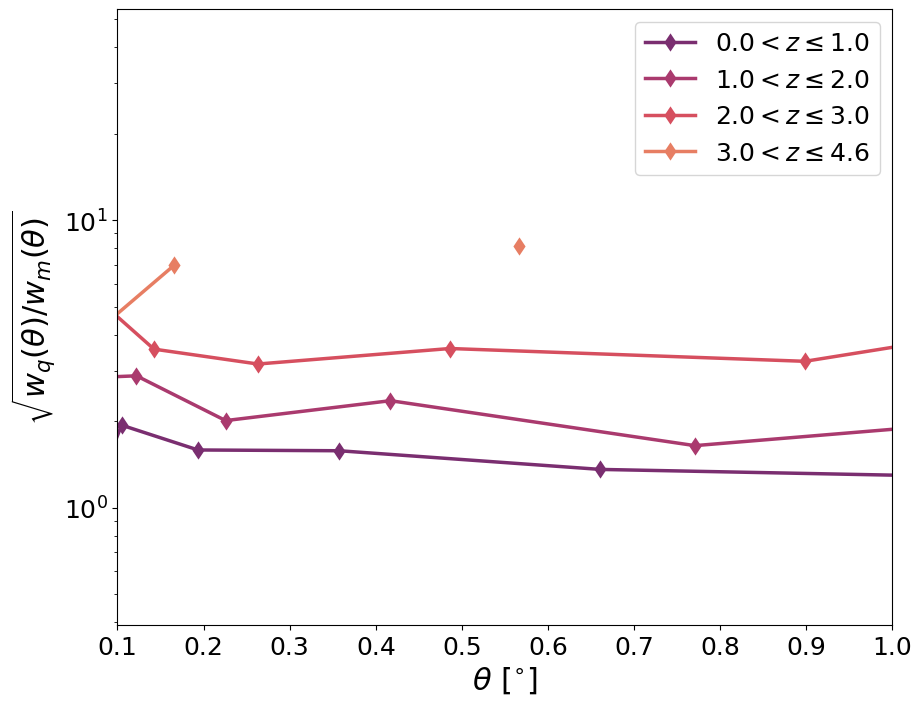

In [42]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
i = 0

ax1 = fig.add_subplot(gs[i])

for j in range(len(z_array)):

    try:
        sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
            G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))))
    except:
        sigma = 0
    try:
        wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_{}_MC_b{}.npy'.format(
            G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
    except:
        pass
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b)))            

    w_m = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [1, 9, 0, 12, 1.5], 2, one_halo = True, two_halo = True, b_z = 1)
    b_q = np.sqrt(wp_zbin_i/w_m)
    ax1.plot(10**(np.log10(quaia.recenter(thetabins[::2])) + j*delta_xlim/2*2), b_q[::2], linewidth = 2.5, color = cmap_theta[j], markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), marker = 'd')

    ax1.set_xlim(0.1, 1)
    ax1.set_yscale('log')
    ax1.set_ylabel(r"$\sqrt{w_q(\theta)/w_m(\theta)}$")
    ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
    ax1.legend(loc = 'upper right')

# plt.savefig('../figures/wtheta_Lmax.pdf', bbox_inches = 'tight')
plt.show()

<>:26: SyntaxWarning: invalid escape sequence '\l'
<>:26: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_129223/3546966387.py:26: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(1/a-1, np.nanmean(b_q[linear_mask]), linewidth = 2.5, color = cmap_theta[i], markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), marker = 'd', yerr = np.nanstd(b_q[linear_mask]))


1.515202528166193 Mpc(1/2)
2.008800977281041 Mpc(1/2)
3.1951611908924997 Mpc(1/2)
8.935995135595917 Mpc(1/2)


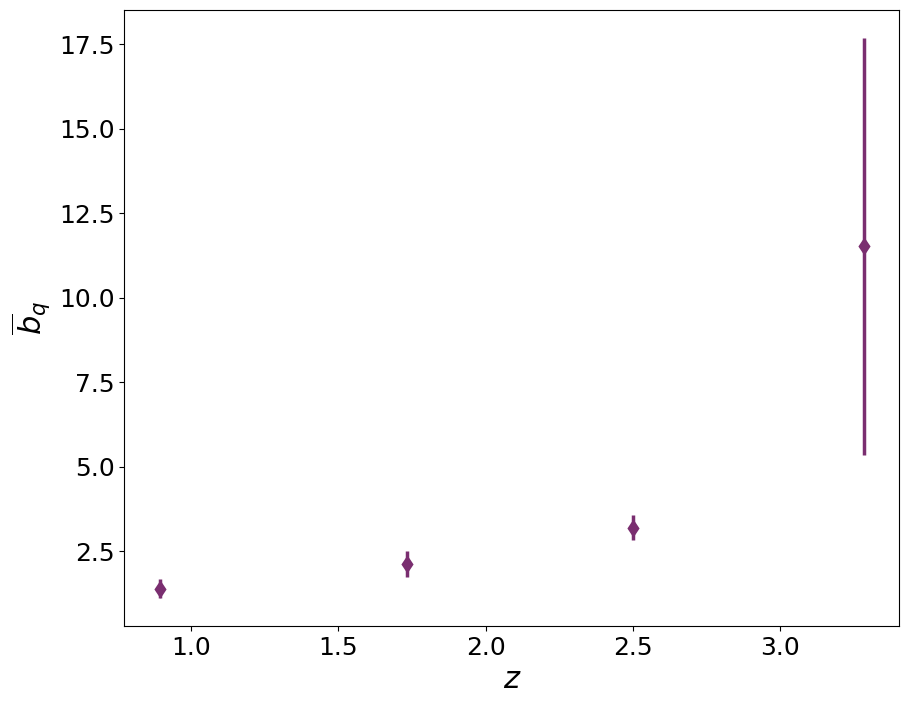

In [43]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1, wspace = 0, hspace = 0.15)
linear_mask = (quaia.recenter(thetabins)>=0.1) & (quaia.recenter(thetabins)<=1)
# remove bottom panel and just print bq somewhere
# plot!
i = 0

ax1 = fig.add_subplot(gs[i])

for j in range(len(z_array)):

    try:
        sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
            G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))))
    except:
        sigma = 0
    try:
        wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_{}_MC_b{}.npy'.format(
            G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
    except:
        pass
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b)))            

    w_m = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [1, 9, 0, 12, 1.5], 2, one_halo = True, two_halo = True, b_z = 1)
    b_q = np.sqrt(wp_zbin_i/w_m)
    ax1.errorbar(1/a-1, np.nanmean(b_q[linear_mask]), linewidth = 2.5, color = cmap_theta[i], markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), marker = 'd', yerr = np.nanstd(b_q[linear_mask]))
    print(np.nanmedian(b_q[linear_mask]))

    # ax1.set_xlim(0.1, 1)
    # ax1.set_yscale('log')
    # ax1.set_ylabel(r"$\sqrt{w_q(\theta)/w_m(\theta)}$")
    ax1.set_ylabel(r"$\overline{b}_q$")
    ax1.set_xlabel(r'$z$') 
    # ax1.legend(loc = 'upper right')

plt.savefig('../figures/b_q.pdf', bbox_inches = 'tight')
plt.show()

<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_129223/4277429444.py:35: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(zbin[L_bins[i]], np.nanmean(b_q, axis = 1), linewidth = 2.5, color = cmap_theta[i], markeredgewidth = 2.5, linestyle = '-', label = '$M_i\leq{}$'.format(L_bins[i]), marker = 'd',
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: invalid value encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/astropy/units/quantity.py:653: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *a

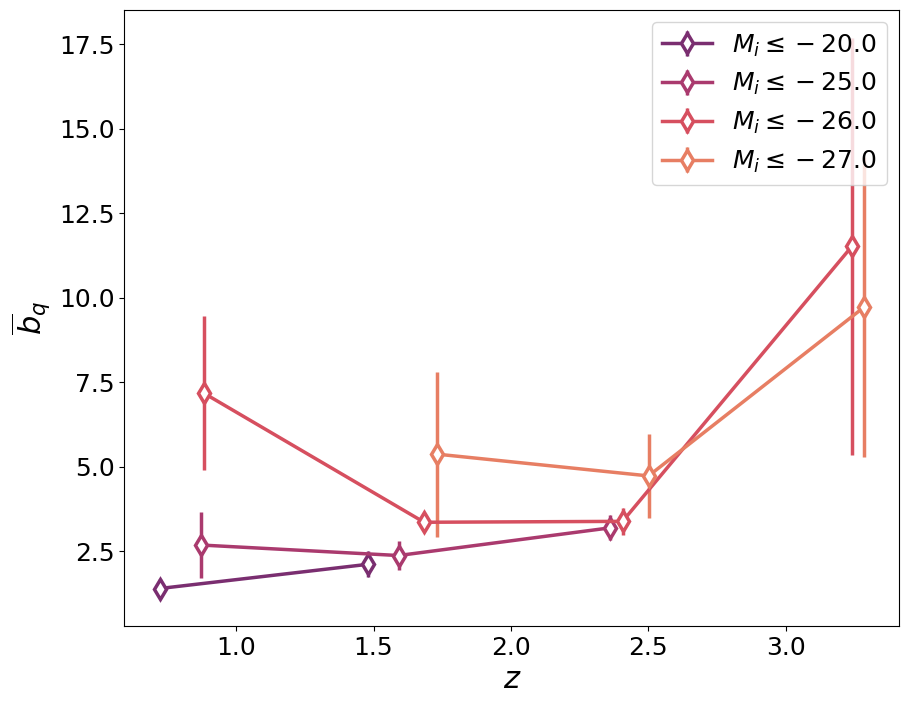

In [44]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1, wspace = 0, hspace = 0.15)
linear_mask = (quaia.recenter(thetabins)>=0.1) & (quaia.recenter(thetabins)<=1)
# remove bottom panel and just print bq somewhere
# plot!
i = 0

ax1 = fig.add_subplot(gs[i])
for i in range(len(L_bins)):
    
    b_q, a = [], []
    
    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
        
            try:
                sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))))
            except:
                sigma = 0
            try:
                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            except:
                pass
            # a.append(float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b))))     
        
            w_m = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [1, 9, 0, 12, 1.5], 2, one_halo = True, two_halo = True, b_z = 1)
            b_q.append(np.sqrt(wp_zbin_i/w_m)[linear_mask])
            
        else:
            b_q.append([np.nan]*np.sum(linear_mask))
        
    ax1.errorbar(zbin[L_bins[i]], np.nanmean(b_q, axis = 1), linewidth = 2.5, color = cmap_theta[i], markeredgewidth = 2.5, linestyle = '-', label = '$M_i\leq{}$'.format(L_bins[i]), marker = 'd', 
                 yerr = np.nanstd(b_q, axis = 1), markerfacecolor = 'white', markersize = 10)
        
    # print(np.nanmean(b_q, axis = 1))
        # print(np.nanmedian(b_q[linear_mask]))

    # ax1.set_xlim(0.1, 1)
    # ax1.set_yscale('log')
    # ax1.set_ylabel(r"$\sqrt{w_q(\theta)/w_m(\theta)}$")
    ax1.set_ylabel(r"$\overline{b}_q$")
    ax1.set_xlabel(r'$z$') 
    ax1.legend()

plt.savefig('../figures/b_q_z.pdf', bbox_inches = 'tight')
plt.show()

<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:39: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_129223/2800603792.py:39: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(zbin[L_bins[i]], np.nanmean(b_q, axis = 1), linewidth = 2.5, color = cmap_theta[i], markeredgewidth = 2.5, linestyle = 'None', label = '$M_i\leq{}$'.format(L_bins[i]), marker = 'd',
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: invalid value encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))
/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/astropy/units/quantity.py:653: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method,

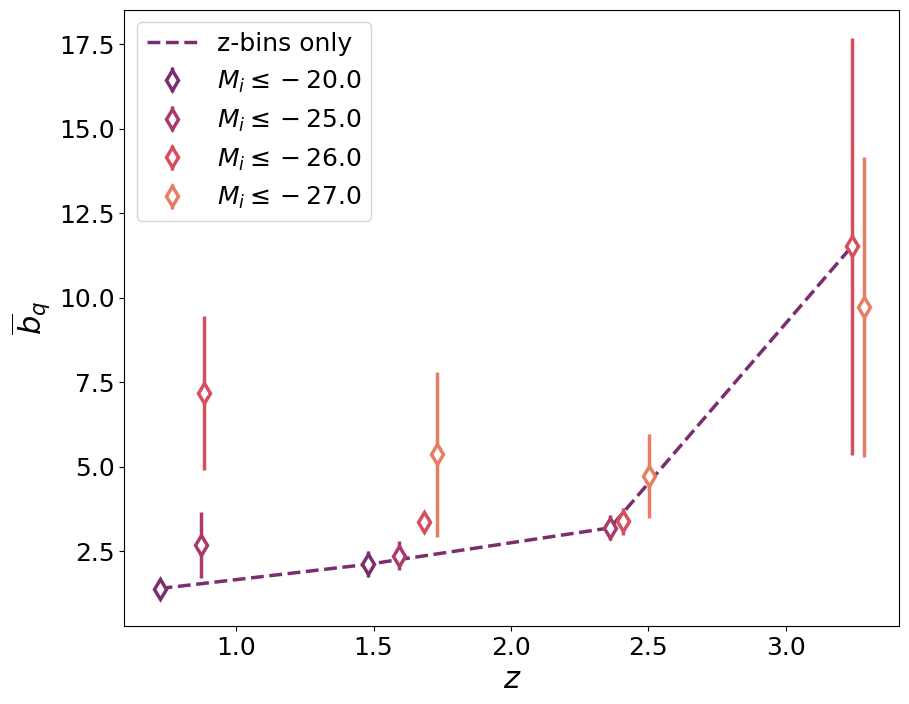

In [45]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1, wspace = 0, hspace = 0.15)
linear_mask = (quaia.recenter(thetabins)>=0.1) & (quaia.recenter(thetabins)<=1)
# remove bottom panel and just print bq somewhere
# plot!
i = 0

ax1 = fig.add_subplot(gs[i])
b_q_null=[]
for i in range(len(L_bins)):
    
    b_q, a = [], []
    
    for j in range(len(z_array)):
        
        try:
            sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))))
        except:
            sigma = 0
        try:
            wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
        except:
            pass
        # a.append(float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b))))     
    
        w_m = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [1, 9, 0, 12, 1.5], 2, one_halo = True, two_halo = True, b_z = 1)

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
            b_q.append(np.sqrt(wp_zbin_i/w_m)[linear_mask])
        
        else:
            b_q.append([np.nan]*np.sum(linear_mask))

        if i ==0:
            b_q_null.append(np.sqrt(wp_zbin_i/w_m)[linear_mask])
        
    ax1.errorbar(zbin[L_bins[i]], np.nanmean(b_q, axis = 1), linewidth = 2.5, color = cmap_theta[i], markeredgewidth = 2.5, linestyle = 'None', label = '$M_i\leq{}$'.format(L_bins[i]), marker = 'd', 
                 yerr = np.nanstd(b_q, axis = 1), markerfacecolor = 'white', markersize = 10)
    
# print(np.nanmean(b_q, axis = 1))
    # print(np.nanmedian(b_q[linear_mask]))

# ax1.set_xlim(0.1, 1)
# ax1.set_yscale('log')
# ax1.set_ylabel(r"$\sqrt{w_q(\theta)/w_m(\theta)}$")
ax1.set_ylabel(r"$\overline{b}_q$")
ax1.set_xlabel(r'$z$') 
    # ax1.legend()
    
ax1.plot(zbin[L_bins[0]], np.nanmean(b_q_null, axis = 1), linewidth = 2.5, color = cmap_theta[0], markeredgewidth = 2.5, linestyle = '--', label = 'z-bins only')
ax1.legend(loc = 'upper left')

# plt.savefig('../figures/b_q_z.pdf', bbox_inches = 'tight')
plt.show()

In [46]:
np.nanmean(b_q_null, axis = 1)

array([ 1.39291359,  2.10983187,  3.18880297, 11.52411228])

<>:39: SyntaxWarning: invalid escape sequence '\l'
<>:39: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_129223/2041168004.py:39: SyntaxWarning: invalid escape sequence '\l'
  ax1.errorbar(L_bins, np.nanmean(b_q, axis = 1), linewidth = 2.5, color = cmap_theta[j], markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), marker = 'd',
/tmp/ipykernel_129223/2041168004.py:38: RuntimeWarning: Mean of empty slice
  print(np.nanmean(b_q, axis = 1)[-1])
/tmp/ipykernel_129223/2041168004.py:39: RuntimeWarning: Mean of empty slice
  ax1.errorbar(L_bins, np.nanmean(b_q, axis = 1), linewidth = 2.5, color = cmap_theta[j], markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), marker = 'd',


nan
5.369383043972058
4.7253788267261925
9.721228150019684


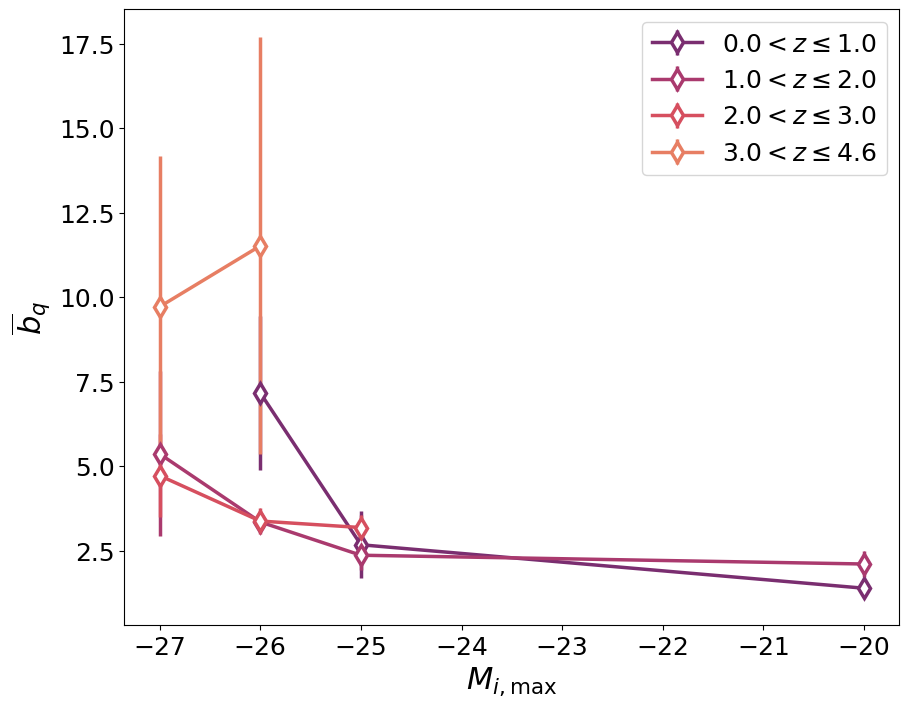

In [47]:
fig = plt.figure(figsize = (10, 8))
gs = gridspec.GridSpec(1, 1, wspace = 0, hspace = 0.15)
linear_mask = (quaia.recenter(thetabins)>=0.1) & (quaia.recenter(thetabins)<=1)
# remove bottom panel and just print bq somewhere
# plot!
# i = 0

ax1 = fig.add_subplot(gs[0])

for j in range(len(z_array)):
    
    b_q, a = [], []
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
        
            try:
                sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))))
            except:
                sigma = 0
            try:
                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_{}_MC_b{}.npy'.format(
                    G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
            except:
                pass
            a.append(float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b))))            
            
            w_m = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [1, 9, 0, 12, 1.5], 2, one_halo = True, two_halo = True, b_z = 1)
            b_q.append(np.sqrt(wp_zbin_i/w_m)[linear_mask])
            # print(np.sqrt(wp_zbin_i/w_m)[linear_mask])
        else:
            b_q.append([np.nan]*np.sum(linear_mask) )

    # print(b_q[1])
    # print(np.nanmean(b_q, axis = 1))
    print(np.nanmean(b_q, axis = 1)[-1])
    ax1.errorbar(L_bins, np.nanmean(b_q, axis = 1), linewidth = 2.5, color = cmap_theta[j], markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]), marker = 'd', 
                 yerr = np.nanstd(b_q, axis = 1), markerfacecolor = 'white', markersize = 10)

    ax1.set_ylabel(r"$\overline{b}_q$")
    ax1.set_xlabel(r'$M_{i, \mathrm{max}}$') 
    ax1.legend()

plt.savefig('../figures/b_q_L.pdf', bbox_inches = 'tight')
plt.show()

<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_129223/250058644.py:29: SyntaxWarning: invalid escape sequence '\l'
  yerr = sigma[::2], markeredgewidth = 2.5, linestyle = 'None', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5
/tmp/ipykernel_129223/250058644.py:32: SyntaxWarning: invalid escape sequence '\l'
  ax1.plot(10**(np.log10(quaia.recenter(thetabins)) + j*delta_xlim/2*2), w_m, linewidth = 2.5, color = cmap_theta[i], markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
/tmp/ipykernel_129223/250058644.py:33: SyntaxWarning: invalid

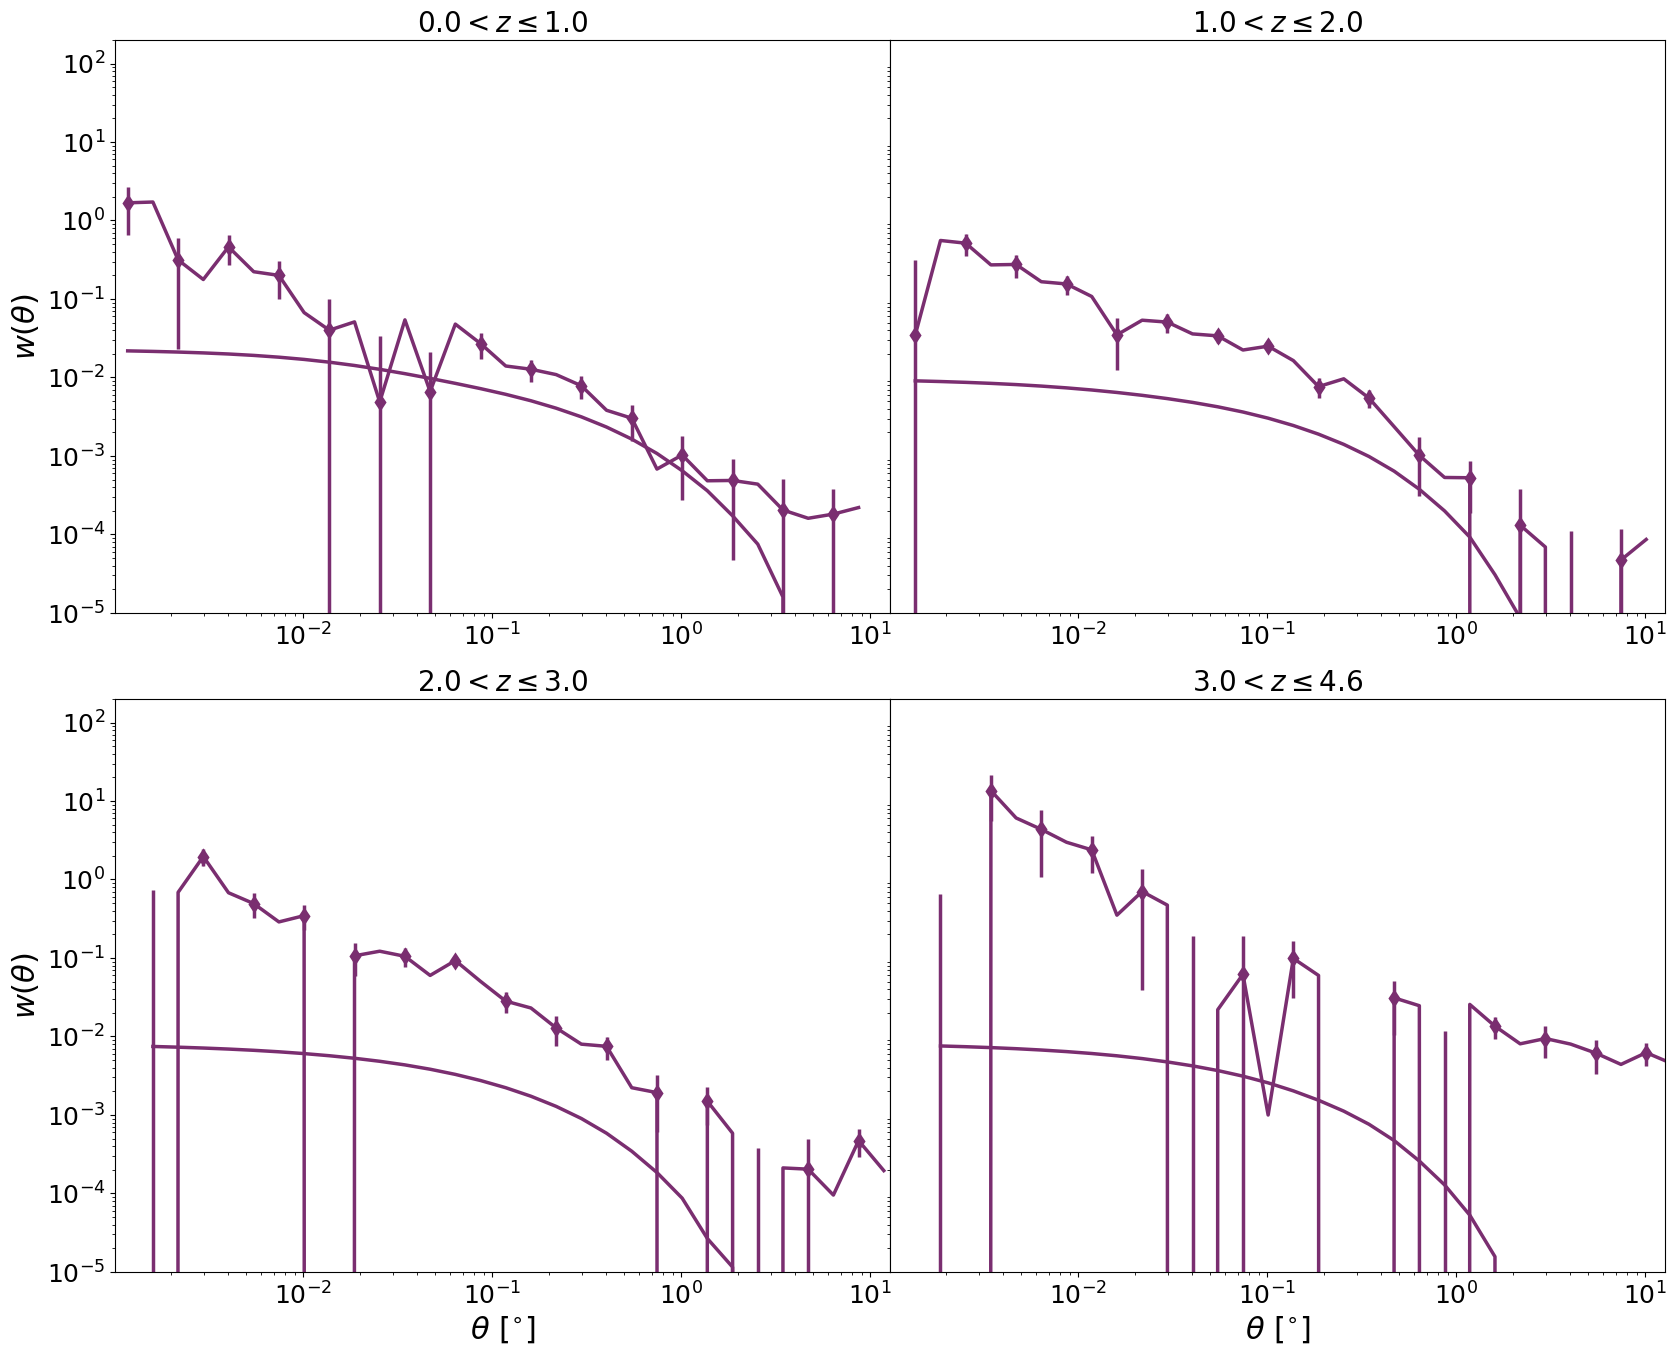

In [48]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)

# remove bottom panel and just print bq somewhere
# plot!
i = 0

for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])
    
    # for i in range(len(L_bins)):

# if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

    try:
        sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
            G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))))
    except:
        sigma = 0
    try:
        wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_{}_MC_b{}.npy'.format(
            G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
    except:
        pass
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b)))            
    
    ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)[::2]) + j*delta_xlim/2*2), wp_zbin_i[::2], linewidth = 2.5, marker = 'd', color = cmap_theta[i],
                yerr = sigma[::2], markeredgewidth = 2.5, linestyle = 'None', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1])) #capsize = 2.5

    w_m = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [1, 9, 0, 12, 1.5], 2, one_halo = True, two_halo = True, b_z = 1)
    ax1.plot(10**(np.log10(quaia.recenter(thetabins)) + j*delta_xlim/2*2), w_m, linewidth = 2.5, color = cmap_theta[i], markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
    ax1.plot(10**(np.log10(quaia.recenter(thetabins)) + j*delta_xlim/2*2), w_m*wp_zbin_i/w_m, linewidth = 2.5, color = cmap_theta[i], markeredgewidth = 2.5, linestyle = '-', label = '${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
    
    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
    ax1.set_xlim(10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim))
    ax1.set_yscale('log')
    ax1.set_xscale('log')
    ax1.set_ylim(1e-5, 2e2)
    
    if j%2==0:
        ax1.set_ylabel(r"$w(\theta)$")
    else:
        ax1.set_yticks([])
    if j > 1:
        ax1.set_xlabel(r'$\theta$ $[^{\circ}]$') 
    # ax1.legend(loc = 'upper right')

# plt.savefig('../figures/wtheta_Lmax.pdf', bbox_inches = 'tight')
plt.show()

## Limit angular scales to $0.001^\circ\geq \theta \geq 10^\circ$

In [49]:
# Create the bins array
rmin = 0.001
rmax = 10.0
nbins = 30 #20 #30 #20
thetabins = np.logspace(np.log10(rmin), np.log10(rmax), nbins+1)
np.log10(thetabins), quaia.recenter(np.log10(thetabins)), np.diff(np.log10(thetabins))

(array([-3.        , -2.86666667, -2.73333333, -2.6       , -2.46666667,
        -2.33333333, -2.2       , -2.06666667, -1.93333333, -1.8       ,
        -1.66666667, -1.53333333, -1.4       , -1.26666667, -1.13333333,
        -1.        , -0.86666667, -0.73333333, -0.6       , -0.46666667,
        -0.33333333, -0.2       , -0.06666667,  0.06666667,  0.2       ,
         0.33333333,  0.46666667,  0.6       ,  0.73333333,  0.86666667,
         1.        ]),
 array([-2.93333333e+00, -2.80000000e+00, -2.66666667e+00, -2.53333333e+00,
        -2.40000000e+00, -2.26666667e+00, -2.13333333e+00, -2.00000000e+00,
        -1.86666667e+00, -1.73333333e+00, -1.60000000e+00, -1.46666667e+00,
        -1.33333333e+00, -1.20000000e+00, -1.06666667e+00, -9.33333333e-01,
        -8.00000000e-01, -6.66666667e-01, -5.33333333e-01, -4.00000000e-01,
        -2.66666667e-01, -1.33333333e-01, -2.35922393e-16,  1.33333333e-01,
         2.66666667e-01,  4.00000000e-01,  5.33333333e-01,  6.66666667e-01,
       

# Select fiducial parameters

In [50]:
marker = ['o', 'd']

In [51]:
log_thetamin = -2.8 #-1
log_thetamax = 0.0
theta_mask=(quaia.recenter(np.log10(thetabins))>=log_thetamin) & (quaia.recenter(np.log10(thetabins))<=log_thetamax)
nbins_mask = np.sum(theta_mask)
dlogz = 0.001 #01
sample = 'auto'
nlive = 1500 #2000
ndim_array = [2,3]

In [52]:
quantile = [0.16, 0.5, 0.84]

### Solve for $\chi_c^2=\Delta^T x$ where $Cx=\Delta$

In [53]:
hartlap = (N_jk-nbins_mask-2)/(N_jk-1)
hartlap, nbins_mask

(0.5306122448979592, 22)

In [54]:
def f0_GLS_solve(x, a, C, wp, H0_c_dN_dz_norm, ndim, cosmo = cosmo_planck18, rpmask = theta_mask, hartlap = hartlap, #, fduty = 0, 
                 rpbins = thetabins, bins = bins_m): #, theta_mask = theta_mask):
    
    fduty, M_min, Alpha, sigma = [*x,0][:4]
    
    wp_2h_zbin = sampler.wtheta_2h_dynesty(bins, H0_c_dN_dz_norm.value, [fduty, M_min, sigma, np.log10(12*10**M_min), Alpha], ndim)#, 
    
    if isinstance(rpmask, bool):
        rpmask = [rpmask]*len(quaia.recenter(rpbins))
    delta = (wp-wp_2h_zbin)[rpmask]
    ix_grid = np.ix_(rpmask, rpmask)
    
    return delta.T @ (hartlap*np.linalg.solve(C[ix_grid], delta))

### Add a number density constraint

In [55]:
def constraint(x, a, n_q, cosmo = cosmo_planck18, error = 0.05, #recenter_thetabins = False, #True, 
               hmf = hmf, n_bins = n_bins, bins_m = bins_m):
    
    fduty, M_min, Alpha, sigma = [*x, 0][:4] # fduty,
    
    _, n_c, n_s = sampler.HOD_2h(bins_m, M_min, fduty, sigma, a, np.log10(12*10**M_min), Alpha, ndim, cosmo = cosmo)
    
    n_q_theory = M(bins_m, n_c + n_s, a = a, cosmo = cosmo, recenter = False, hmf= hmf)[1].value

    return error-np.abs(n_q_theory-n_q)/n_q

In [56]:
diag = False

In [57]:
ix_grid = np.ix_(theta_mask, theta_mask)

In [96]:
ylabels = ['\log_{10}(M_{min}/M_\odot)', r'\alpha', '\Sigma']

<>:1: SyntaxWarning: invalid escape sequence '\l'
<>:1: SyntaxWarning: invalid escape sequence '\S'
<>:1: SyntaxWarning: invalid escape sequence '\l'
<>:1: SyntaxWarning: invalid escape sequence '\S'
/tmp/ipykernel_129223/2714271075.py:1: SyntaxWarning: invalid escape sequence '\l'
  ylabels = ['\log_{10}(M_{min}/M_\odot)', r'\alpha', '\Sigma']
/tmp/ipykernel_129223/2714271075.py:1: SyntaxWarning: invalid escape sequence '\S'
  ylabels = ['\log_{10}(M_{min}/M_\odot)', r'\alpha', '\Sigma']


In [58]:
rng = np.random.default_rng(0)

In [59]:
# def f_duty(j, i, ndim, dlogz, nlive, G_hi = G_hi, log_thetamin = log_thetamin, nbins_mask = nbins_mask, cosmo = cosmo, sample = sample, 
#          rmin = rmin, rmax = rmax, N = N, b = b, bins_m = bins_m, Sigma = None, quantile = quantile, a = None, i_null = None):

#     if Sigma is not None:
#         sigma = '_Sigma{:.1f}'.format(Sigma)
#     else:
#         sigma=''

#     if i_null is None:
#         i_null = i
#     file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
#                     G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i_null], cosmo, ndim, sigma, dlogz,
#         nlive, sample) 
                
#     # read the results
#     with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
#         results = pickle.load(fp)

#     samples, weights = results.samples, results.importance_weights()
    
#     # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
#     quantiles = [dyfunc.quantile(samples[:, i], quantile, weights=weights) 
#                  for i in range(samples.shape[1])]

#     # Compute weighted mean and covariance.
#     mean, cov = dyfunc.mean_and_cov(samples, weights)

#     quantiles = np.array(quantiles)
#     quantiles[:,1] = mean

#     equal_weight_samples = dyfunc.resample_equal(samples, weights)

#     if a is None:
#         a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
#                                                                                       cosmo, b)))
        
#     n_dm = []
#     for k in range(len(equal_weight_samples[:,0])):
#         if ndim == 2:
#             n_c=sampler.N_c(bins_m, equal_weight_samples[:,0][k], 1, ndim)
#         else:
#             n_c=sampler.N_c(bins_m, equal_weight_samples[:,0][k], 1, ndim, sigma = equal_weight_samples[:,2][k])
#         n_s = sampler.N_s(bins_m, 1, 10**equal_weight_samples[:,0][k], 12*10**equal_weight_samples[:,0][k], 
#                          equal_weight_samples[:,1][k])
#         n_m = n_c+n_s
    
#         n_dm.append(M(bins_m, n_m, a = a, cosmo = cosmo_planck18, recenter = False)[1].value) #[:,0]
    
#     equal_weight_samples_fduty = np.log10(n_q[L_bins[i]][j]/n_dm)
    
#     # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
#     lo, mid, hi = dyfunc.quantile(equal_weight_samples_fduty, quantile)

#     # Compute weighted mean and covariance.
#     mid = np.mean(equal_weight_samples_fduty)
    
#     return np.append(np.array([lo, mid, hi])[:,None].T, quantiles, axis = 0), np.append(equal_weight_samples_fduty[:,None], equal_weight_samples, axis = 1)

In [60]:
def f_duty(j, i, ndim, dlogz, nlive, G_hi = G_hi, log_thetamin = log_thetamin, nbins_mask = nbins_mask, cosmo = cosmo, sample = sample, 
         rmin = rmin, rmax = rmax, N = N, b = b, bins_m = bins_m, Sigma = None, quantile = quantile, a = None, i_null = None, rstate = rng):

    if Sigma is not None:
        sigma = '_Sigma{:.1f}'.format(Sigma)
    else:
        sigma=''

    if i_null is None:
        i_null = i
    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                    G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i_null], cosmo, ndim, sigma, dlogz,
        nlive, sample) 
                
    # read the results
    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
        results = pickle.load(fp)

    samples, weights = results.samples, results.importance_weights()
    
    # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
    quantiles = [dyfunc.quantile(samples[:, i], quantile, weights=weights) 
                 for i in range(samples.shape[1])]

    # Compute weighted mean and covariance.
    mean, cov = dyfunc.mean_and_cov(samples, weights)

    quantiles = np.array(quantiles)
    quantiles[:,1] = mean

    equal_weight_samples = dyfunc.resample_equal(samples, weights, rstate = rstate)

    if a is None:
        a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
                                                                                      cosmo, b)))
        
    n_dm = []
    for k in range(len(equal_weight_samples[:,0])):
        if ndim == 2:
            n_c=sampler.N_c(bins_m, equal_weight_samples[:,0][k], 1, ndim)
        else:
            n_c=sampler.N_c(bins_m, equal_weight_samples[:,0][k], 1, ndim, sigma = equal_weight_samples[:,2][k])
        n_s = sampler.N_s(bins_m, 1, 10**equal_weight_samples[:,0][k], 12*10**equal_weight_samples[:,0][k], 
                         equal_weight_samples[:,1][k])
        n_m = n_c+n_s
    
        n_dm.append(M(bins_m, n_m, a = a, cosmo = cosmo_planck18, recenter = False)[1].value) #[:,0]
    
    equal_weight_samples_fduty = np.log10(n_q[L_bins[i]][j]/n_dm)
    
    # Get median and 1-sigma (16th, 50th, 84th percentiles) for each parameter
    lo, mid, hi = dyfunc.quantile(equal_weight_samples_fduty, quantile)

    # Compute weighted mean and covariance.
    mid = np.mean(equal_weight_samples_fduty)
    
    return np.append(np.array([lo, mid, hi])[:,None].T, quantiles, axis = 0), np.append(equal_weight_samples_fduty[:,None], equal_weight_samples, axis = 1)

In [61]:
def chi2(j, i, ndim, dlogz, nlive, G_hi = G_hi, log_thetamin = log_thetamin, nbins_mask = nbins_mask, cosmo = cosmo, sample = sample, 
         rmin = rmin, rmax = rmax, N = N_jk, b = b, diag = diag, H0_c_dN_dz_norm = H0_c_dN_dz_norm, bins_m = bins_m, Sigma = None, 
         a = None, i_null = None, L_bins = L_bins, theta_mask = theta_mask):

    if a is None:
        a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
                                                                                  cosmo, b)))

    if i_null is None:
        i_null = i

    quantiles = f_duty(j, i, ndim, dlogz, nlive, G_hi = G_hi, log_thetamin = log_thetamin, nbins_mask = nbins_mask, cosmo = cosmo, 
                       sample = sample, rmin = rmin, rmax = rmax, N = N, b = b, bins_m = bins_m, Sigma = Sigma, a = a, i_null = i_null)[0]
    print(quantiles)
    x = quantiles[:,1]
    
    C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
            G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
    if diag == True:
        C*=np.identity(len(C))
    
    wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
        G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))

    # print(x)
    # print(a)
    # print(C[0])
    # print(wp_zbin_i)
    # print(H0_c_dN_dz_norm[L_bins[i]][j])
    # print(ndim)
    
    chi2 = f0_GLS_solve(x, a, C, wp_zbin_i, H0_c_dN_dz_norm[L_bins[i]][j], ndim, rpmask = theta_mask)

    return chi2, x

In [62]:
# def chi2(j, i, ndim, dlogz, nlive, G_hi = G_hi, log_thetamin = log_thetamin, nbins_mask = nbins_mask, cosmo = cosmo, sample = sample, 
#          rmin = rmin, rmax = rmax, N = N_jk, b = b, diag = diag, H0_c_dN_dz_norm = H0_c_dN_dz_norm, bins_m = bins_m, Sigma = None, 
#          a = None, i_null = None, L_bins = L_bins):

#     if a is None:
#         a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
#                                                                                   cosmo, b)))

#     if i_null is None:
#         i_null = i

#     quantiles = f_duty(j, i, ndim, dlogz, nlive, G_hi = G_hi, log_thetamin = log_thetamin, nbins_mask = nbins_mask, cosmo = cosmo, 
#                        sample = sample, rmin = rmin, rmax = rmax, N = N, b = b, bins_m = bins_m, Sigma = Sigma, a = a, i_null = i_null)[0]
#     print(quantiles)
#     x = quantiles[:,1]
    
#     C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
#             G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N, cosmo, b))
#     if diag == True:
#         C*=np.identity(len(C))
    
#     wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
#         G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))

#     chi2 = f0_GLS_solve(x, a, C, wp_zbin_i, H0_c_dN_dz_norm[L_bins[i]][j], ndim)

#     return chi2, x

In [95]:
def make_contour_cmap(color, n_levels, alpha_min=0, alpha_max=1.0):
    
    cmap = []
    alphas = np.linspace(0,alpha_max,n_levels+1)
    for alpha in alphas:
        rgba = np.array(mcolors.to_rgba(color))
        rgba[-1] = alpha
        cmap.append(rgba)

    return cmap

In [99]:
quantile_2d = 1.0 - np.exp(-0.5 * np.array([1, 2])**2)#, 3])**2)
quantile_2d

array([0.39346934, 0.86466472])

In [101]:
smooth = [[0.04, 0.05, 0.03, 0.05], [0.09, 0.09, 0.08, 0.09]] # 0.05 # 0.08

In [63]:
cmap = sns.color_palette("crest_r", n_colors = len(L_bins))
cmap

[(0.12811691, 0.33411727, 0.51652464),
 (0.14051521, 0.46268258, 0.54653253),
 (0.26693801, 0.58118582, 0.56045121),
 (0.42702625, 0.69711868, 0.56614659)]

In [64]:
cmaps = [cmap_theta, cmap]

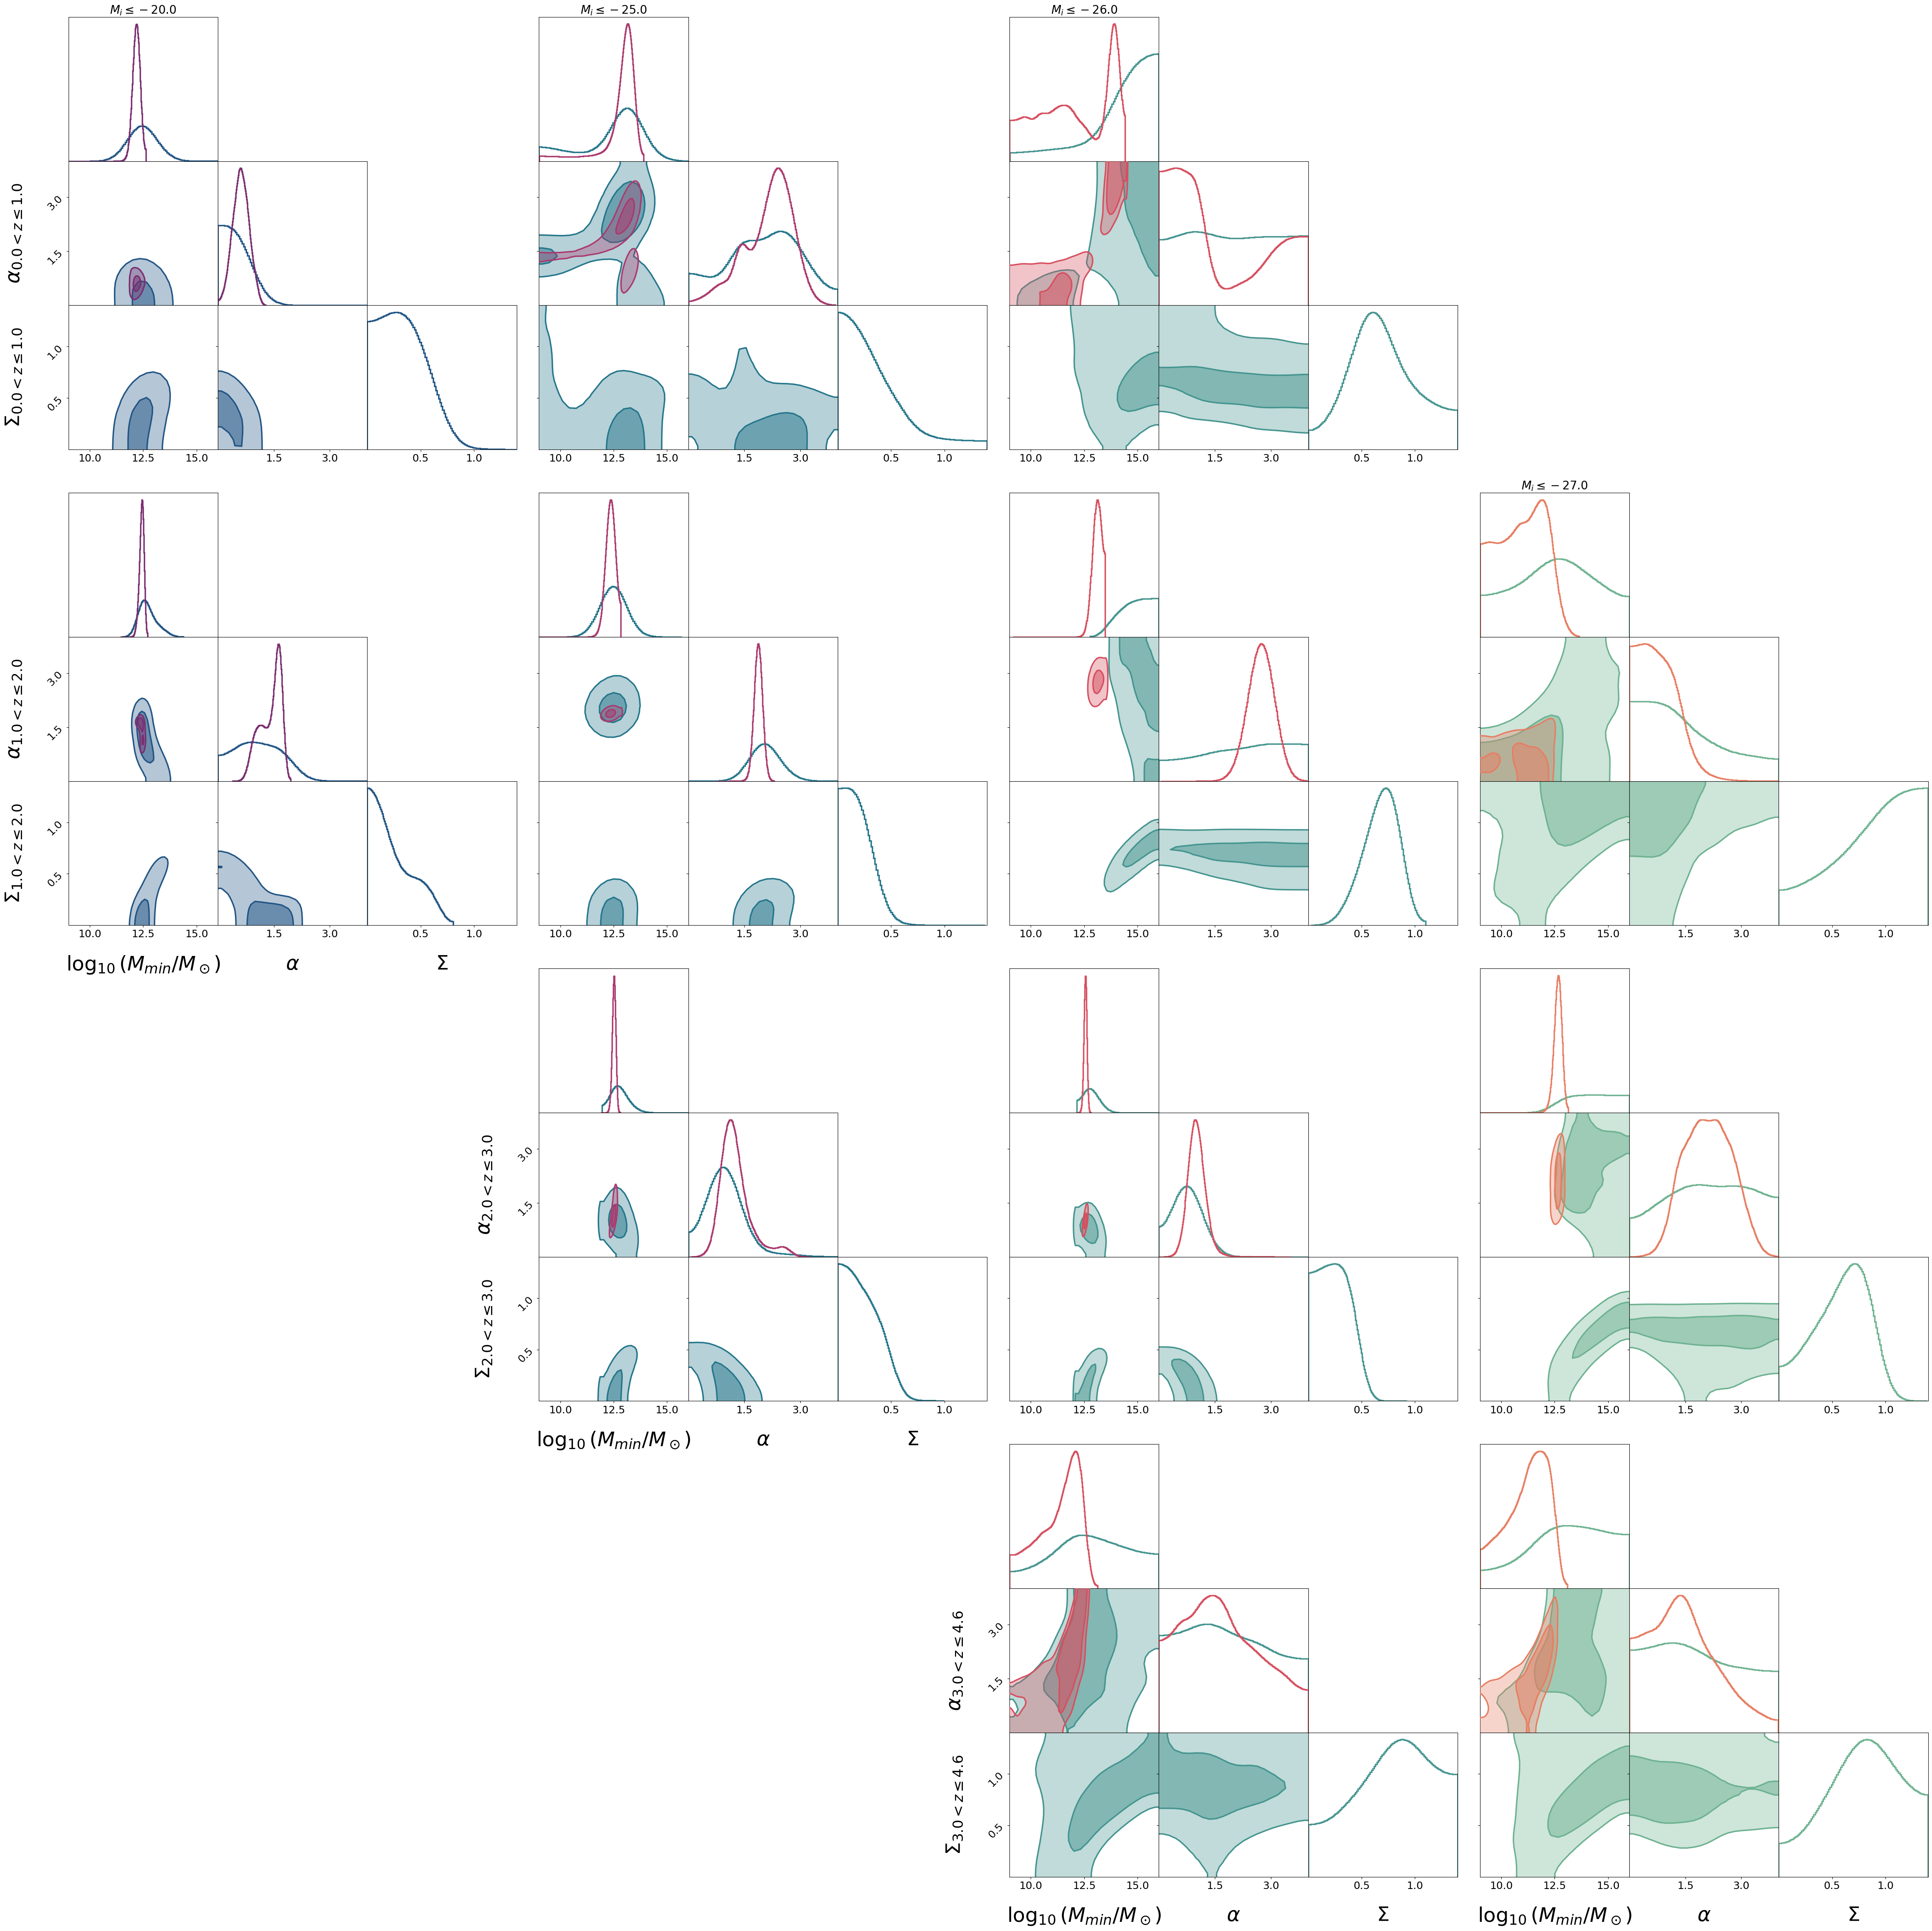

In [113]:
# plot!
fig = plt.figure(figsize=(60, 60))
gs = gridspec.GridSpec(4, 4, wspace=0.05, hspace=0.1)
for j in range(len(z_array)):

    for i in range(len(L_bins)):

        if (((i < 3) and (N_q[L_bins[i]][j] > N_q[L_bins[i+1]][j])) or (i == 3)) and (np.round(N_q[L_bins[i]][j]/1000) > 1):

            # carve an ndim x ndim sub-grid out of this outer cell
            sub_gs = gs[j*4+i].subgridspec(3, 3, wspace=0.0, hspace=0.0) #0.05
            ax = np.array([[fig.add_subplot(sub_gs[r, c]) for c in range(3)]
                                 for r in range(3)])

            custom_lines, legend_labels = [], []
            for k, ndim in enumerate(ndim_array[::-1]):

                try:
                    if ndim == 2:
                        sigma='_Sigma0.0'
                        linewidth = 2.5
                        fill_contours = True
                        plot_density = True
                        no_fill_contours = True
                        zorder = 3
                    else:
                        sigma=''
                        linewidth = 2.5
                        fill_contours = True
                        plot_density = True
                        no_fill_contours = True
                        zorder = 1
                    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}{}_dlogz{}_nlive{}_{}'.format(
                        G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, sigma, dlogz, 
                        nlive, sample) 
                    
                    # read the results
                    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        results = pickle.load(fp)
    
                    samples, weights = results.samples, results.importance_weights()
    
                    contourf_kwargs = {'colors': make_contour_cmap(cmaps[::-1][k][i], len(quantile)), 'zorder': zorder}
                    contour_kwargs = {'colors': [cmaps[::-1][k][i]], 'linewidths': linewidth, 'zorder': zorder}
                    dyplot.cornerplot(results, color=cmaps[::-1][k][i], hist2d_kwargs = {
                        'contourf_kwargs': contourf_kwargs, 'contour_kwargs': contour_kwargs, 'fill_contours': fill_contours, 
                        'plot_density': plot_density, 'no_fill_contours': no_fill_contours}, max_n_ticks=3, 
                                      quantiles=[], quantiles_2d = quantile_2d, title_quantiles = quantile, labels = ['']*ndim,
                                      fig=(fig, ax[:ndim, :ndim]), smooth = smooth[::-1][k][j], hist_kwargs = {
                                          'density': True, 'histtype': 'step', 'linewidth': linewidth, 'alpha': 1})
    
                    quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                                 for k in range(samples.shape[1])]

                    # Compute weighted mean and covariance.
                    mean, cov = dyfunc.mean_and_cov(samples, weights)
                    
                    legend=[]
                    for l, (lo, mid, hi) in enumerate(quantiles):

                        mid = mean[l]
                        
                        legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")
    
                    custom_lines.append(Line2D([0], [0], color=cmaps[::-1][k][i], linestyle='-', linewidth=linewidth))
                    if ndim == 2:
                        legend_labels.append('{}, {}'.format(legend[0], legend[1]))
                    else:
                        legend_labels.append('{}, {}, {}'.format(legend[0], legend[1], legend[2]))
                
                except Exception as e:
                    print(e)#'Unexpected error for bin (j={}, i={}): {}'.format(j, i, e))

                ax1 = ax[1, 0]
                # ax1.legend(handles=custom_lines, labels=legend_labels, loc='upper right', fontsize = 10)
                
                # --- axis limits/labels on the main Mmin-alpha panel ---
                ax[1, 0].set_ylim(0, 4)
                ax[1, 1].set_xlim(0, 4)
                if ndim==3:
                    ax[-1, 0].set_ylim(0, 1.4)
                    ax[-1, 1].set_ylim(0, 1.4)
                    ax[-1, 1].set_xlim(0, 4)
                    ax[-1, -1].set_xlim(0, 1.4)
    
                if j == 0 or ((j == 1) and (i == 3)):
                    ax[0, 0].set_title('$M_i\\leq{}$'.format(L_bins[i]))
                for k, axis in enumerate(ax[:, 0]):
                    axis.set_xlim(9, 16)
                    if not (i == 0 or ((j > 1) and (i < 3) and (i != j))):
                        axis.set_yticklabels([])
                    elif k>0:
                        axis.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[k], z_bins[j], z_bins[j+1]), fontsize = 35)
                for k, axis in enumerate(ax[-1, :]):
                    axis.xaxis.set_label_coords(0.5, -0.2)
                    if j > 2 or ((j > 0) and (i < 2) and (i != j)):
                        # ax1.set_xlabel('${}$'.format(ylabels[0]))
                        axis.set_xlabel('${}$'.format(ylabels[k]), fontsize = 35)
                    plt.setp(axis.get_xticklabels(), rotation=0, ha='center')

fig.savefig('../figures/cornerplot_nolegend.pdf'.format(ndim), bbox_inches='tight')
plt.show()

# Plot results

In [65]:
labels=[r'$\log(f_\mathrm{duty})$', r'$\log_{10} (M_\mathrm{min}/M_\odot)$', r'$\alpha$', r'$\Sigma$']

In [66]:
Sigma = [0, None]

In [67]:
quantiles = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
equal_weight_samples = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
for i in range(len(L_bins)):    

    for j in range(len(z_array)):

        for l, ndim in enumerate(ndim_array):

            if np.round(N_q[L_bins[i]][j]/1000)>1:

                quantiles_bin, equal_weight_samples_bin = f_duty(j, i, ndim, dlogz, nlive, Sigma = Sigma[l], log_thetamin = log_thetamin, nbins_mask = nbins_mask)
                quantiles[ndim][L_bins[i]].append(quantiles_bin)
                equal_weight_samples[ndim][L_bins[i]].append(equal_weight_samples_bin)
                
            else:
                
                quantiles[ndim][L_bins[i]].append([[np.nan]*3])
                equal_weight_samples[ndim][L_bins[i]].append([np.nan]*(ndim+1))

/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:166: RuntimeWarning: invalid value encountered in power
  n_m = fduty*((bins_m-M0)/M1)**alpha


In [68]:
err_labels = ['log10(f_duty)', 'log10(M_min)', 'alpha', 'Sigma']

In [69]:
for k, ndim in enumerate(ndim_array):

    print('ndim: {}'.format(ndim))

    for i in range(len(L_bins)):
    
        print('M_i<={}'.format(L_bins[i]))
            
        for j in z_array:
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
            
                print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))
                # print(quantiles[ndim][L_bins[i]][j][0])

                lo, mid, hi = quantiles[ndim][L_bins[i]][j][0]
                
                print(f"{err_labels[0]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}\n")

ndim: 2
M_i<=-20.0
0.0<z<=1.0
log10(f_duty)=-2.73^{+0.12}_{-0.12}

1.0<z<=2.0
log10(f_duty)=-2.34^{+0.10}_{-0.11}

M_i<=-25.0
0.0<z<=1.0
log10(f_duty)=-2.64^{+0.72}_{-0.50}

1.0<z<=2.0
log10(f_duty)=-2.53^{+0.19}_{-0.18}

2.0<z<=3.0
log10(f_duty)=-2.21^{+0.16}_{-0.12}

M_i<=-26.0
0.0<z<=1.0
log10(f_duty)=-3.99^{+2.38}_{-2.23}

1.0<z<=2.0
log10(f_duty)=-1.64^{+0.16}_{-0.19}

2.0<z<=3.0
log10(f_duty)=-2.19^{+0.11}_{-0.12}

3.0<z<=4.6
log10(f_duty)=-4.61^{+1.44}_{-1.61}

M_i<=-27.0
1.0<z<=2.0
log10(f_duty)=-5.10^{+1.25}_{-1.35}

2.0<z<=3.0
log10(f_duty)=-2.36^{+0.23}_{-0.24}

3.0<z<=4.6
log10(f_duty)=-4.91^{+1.45}_{-1.53}

ndim: 3
M_i<=-20.0
0.0<z<=1.0
log10(f_duty)=-2.56^{+0.19}_{-0.19}

1.0<z<=2.0
log10(f_duty)=-2.14^{+0.27}_{-0.22}

M_i<=-25.0
0.0<z<=1.0
log10(f_duty)=-3.14^{+1.24}_{-2.15}

1.0<z<=2.0
log10(f_duty)=-2.41^{+0.20}_{-0.19}

2.0<z<=3.0
log10(f_duty)=-1.98^{+0.28}_{-0.27}

M_i<=-26.0
0.0<z<=1.0
log10(f_duty)=-2.05^{+1.88}_{-2.26}

1.0<z<=2.0
log10(f_duty)=-0.04^{+0.71}_{-0.

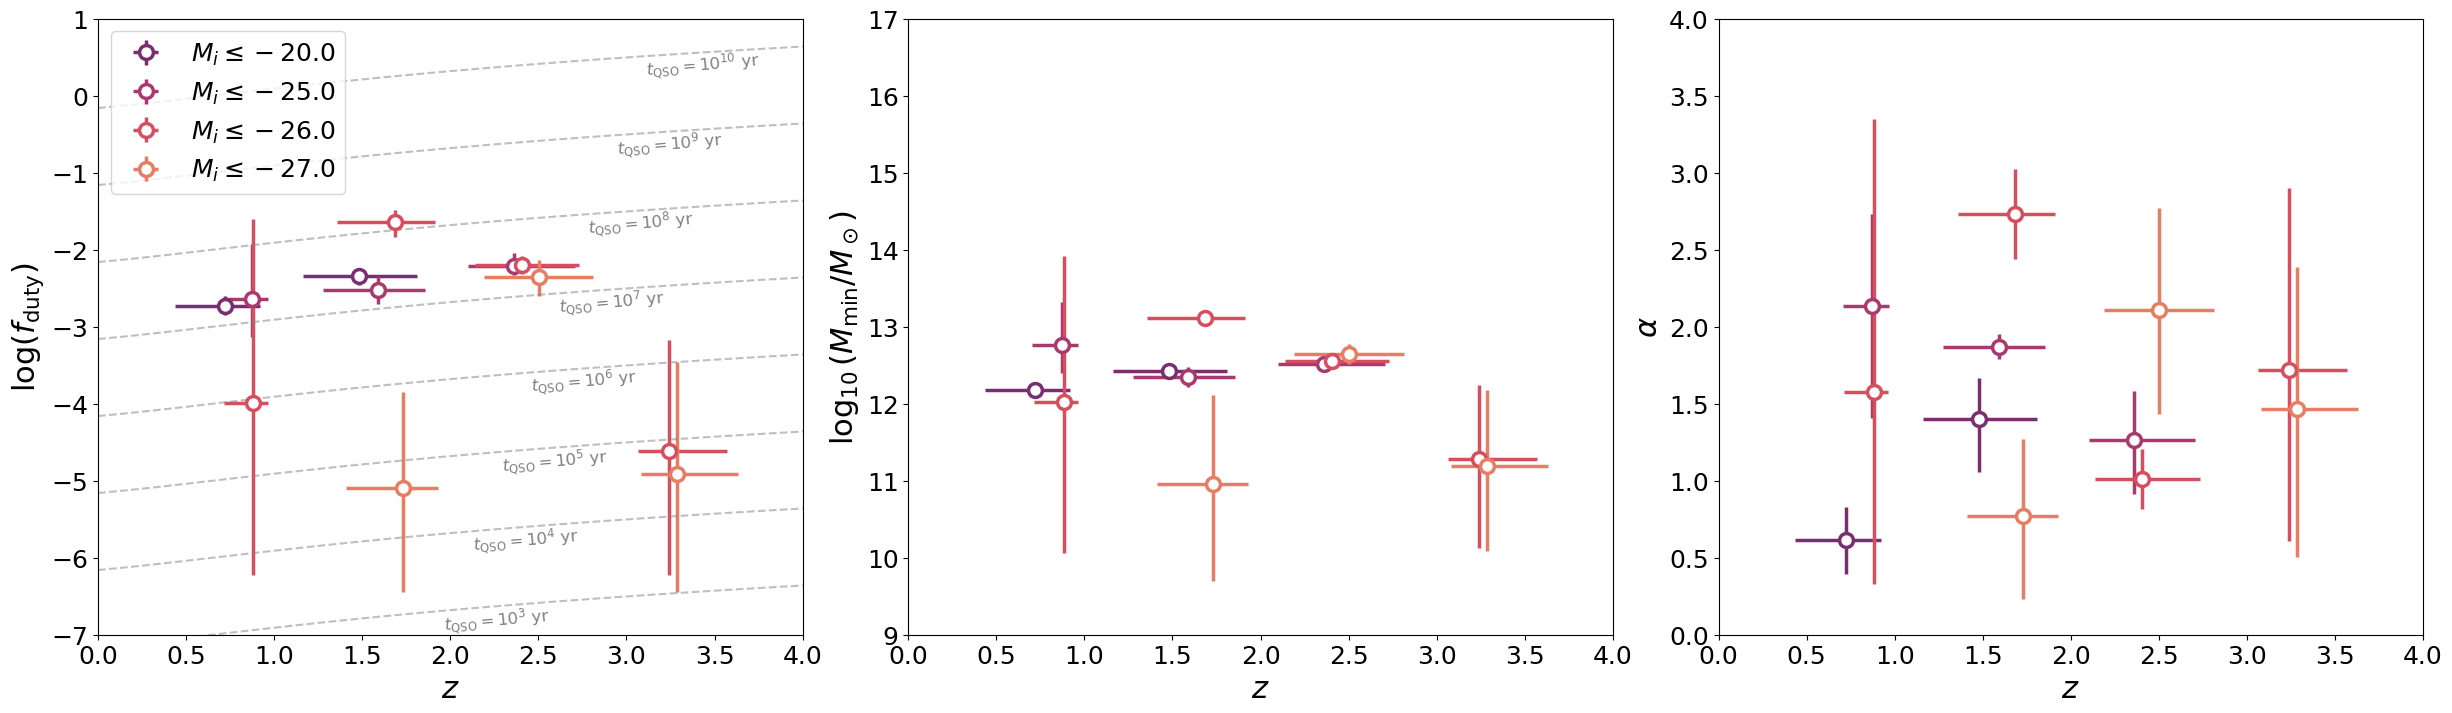

In [93]:
fig = plt.figure(figsize = (30, 8))
gs = gridspec.GridSpec(1, 3, wspace = 0.15, hspace = 0.15)
ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])
ndim = 2
ax = [ax1, ax2, ax3] #, ax4]

for i in range(len(L_bins)):    

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                            G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
            zbin = 1/a-1
            xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]
            
            for l, (lo, mid, hi) in enumerate(quantiles[ndim][L_bins[i]][j]):
                
                ax[l].errorbar(zbin, mid, yerr = [[mid-lo], [hi-mid]], 
                     xerr = xerr, linestyle = 'none', marker = 'o', label = r'$M_i\leq{}$'.format(L_bins[i]),
                     color = cmap_theta[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)#,
                ax[l].set_ylabel(labels[l])
                ax[l].set_xlabel('$z$')
                ax[l].set_xlim(0, 4)

h, l = ax1.get_legend_handles_labels()
label, ind = np.unique(l, return_index = True)
ax1.legend([h[i] for i in ind], label)

d = 1
start = 12
z_linspace = np.linspace(0,8)
for i, t in enumerate([1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    ax1.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.25, 
                r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

ax1.set_ylim(-7,1)
ax2.set_ylim(9,17)#16)
ax3.set_ylim(0, 4)

# plt.savefig('../figures/constraints_step.pdf', bbox_inches = 'tight')
plt.show()

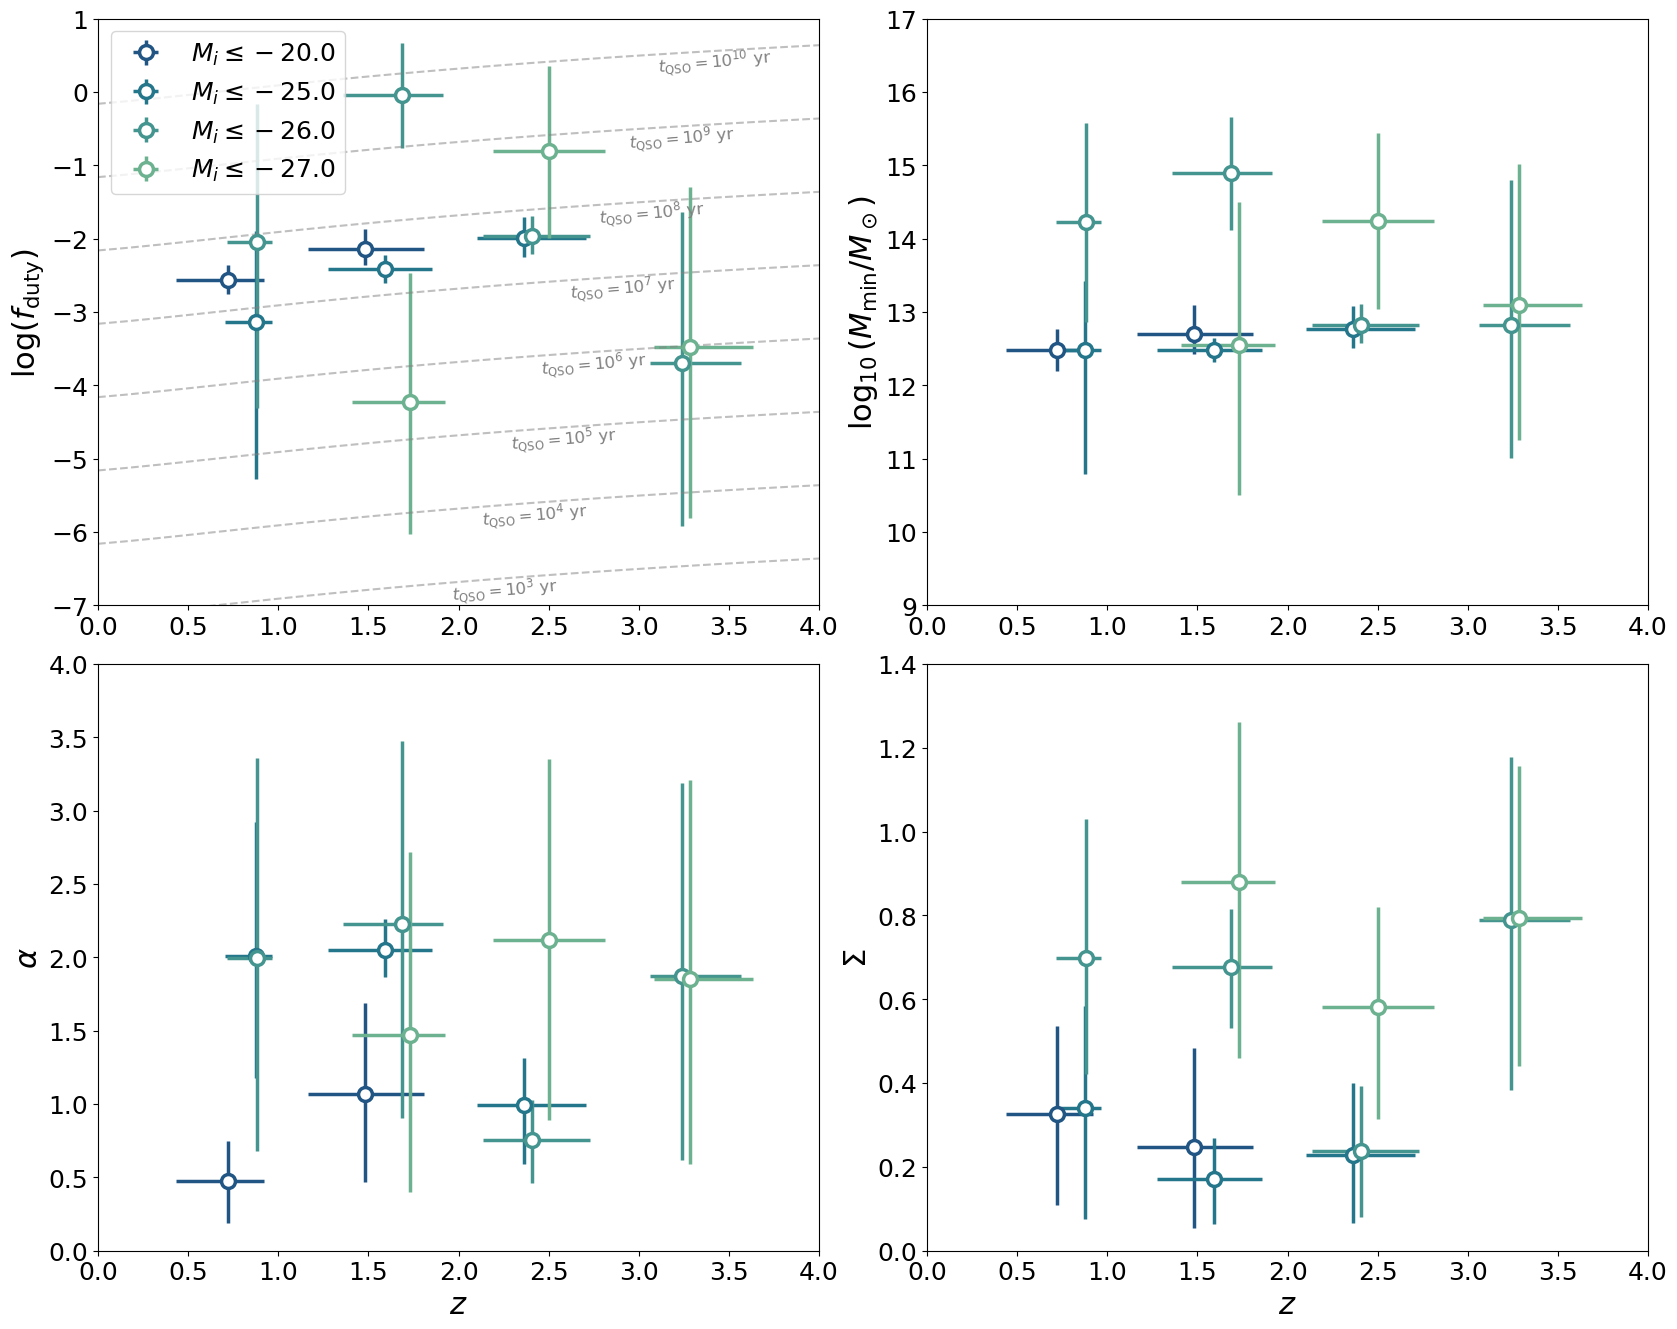

In [71]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0.15, hspace = 0.1)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])
ax4 = fig.add_subplot(gs[3])
ndim = 3
ax = [ax1, ax2, ax3, ax4]
for i in range(len(L_bins)):    

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                            G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
            zbin = 1/a-1
            xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]
            
            for l, (lo, mid, hi) in enumerate(quantiles[ndim][L_bins[i]][j]):
                ax[l].errorbar(zbin, mid, yerr = [[mid-lo], [hi-mid]], 
                     xerr = xerr, linestyle = 'none', marker = 'o', label = r'$M_i\leq{}$'.format(L_bins[i]),
                     color = cmap[i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)#,
                ax[l].set_ylabel(labels[l])
                ax[l].set_xlim(0, 4)

ax3.set_xlabel('$z$')
ax4.set_xlabel('$z$')

h, l = ax1.get_legend_handles_labels()
label, ind = np.unique(l, return_index = True)
ax1.legend([h[i] for i in ind], label)

d = 1
start = 12
z_linspace = np.linspace(0,8)
for i, t in enumerate([1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    ax1.text(z_linspace[start:][::d][i], np.log10(fduty_linspace)[start:][::d][i]-0.25, 
                r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

ax1.set_ylim(-7,1)
ax2.set_ylim(9,17)#6)
ax3.set_ylim(0, 4)
ax4.set_ylim(0, 1.4)

plt.savefig('../figures/constraints_erfc.pdf', bbox_inches = 'tight')
plt.show()

## Compare to literature

In [72]:
z_centers_eft    = [2.50, 2.29, 2.51, 3.02, 2.50, 2.50, 2.50][:4]
z_err_lo_eft     = [0.30, 0.09, 0.13, 0.38, 0.30, 0.30, 0.30][:4]
z_err_hi_eft     = [0.30, 0.09, 0.13, 0.38, 0.30, 0.30, 0.30][:4]

fduty_eft        = np.log10([0.00734, 0.0162, 0.0061, 0.00145, 0.0019, 0.0023, 0.0044])[:4]
fduty_err_hi_eft = np.log10(10**fduty_eft+[0.0014,  0.0031, 0.0016, 0.0003,  0.0004, 0.0006, 0.0015][:4])-fduty_eft
fduty_err_lo_eft = fduty_eft-np.log10(10**fduty_eft-[0.0011,  0.0025, 0.0014, 0.0002,  0.0003, 0.0004, 0.0008][:4]) #table 7 https://arxiv.org/pdf/1507.08380

In [73]:
Mmin_eft        = np.log10(np.array([0.93, 1.39, 0.82, 0.35, 1.03, 0.92, 1.26])*1e12/Planck18.h)[:4]
Mmin_err_hi_eft = np.log10(np.add([0.11, 0.16, 0.15, 0.04, 0.12, 0.12, 0.26],[0.93, 1.39, 0.82, 0.35, 1.03, 0.92, 1.26])[:4]*1e12/Planck18.h)-Mmin_eft
Mmin_err_lo_eft = Mmin_eft-np.log10(np.subtract([0.93, 1.39, 0.82, 0.35, 1.03, 0.92, 1.26], [0.09, 0.15, 0.14, 0.07, 0.10, 0.16, 0.15])[:4]*1e12/Planck18.h) #table 7 https://arxiv.org/pdf/1507.08380

In [74]:
z_centers_2    = [1.05, 1.35, 1.65, 2.00, 1.55][:-1]
z_err_lo_2     = [0.15, 0.15, 0.15, 0.20, 0.65][:-1]
z_err_hi_2     = [0.15, 0.15, 0.15, 0.20, 0.65][:-1]

fduty_2        = np.log10([0.0091, 0.0183, 0.0355, 0.0422, 0.0292])[:-1]
fduty_err_hi_2 = np.log10(10**fduty_2+[0.0027, 0.0028, 0.0133, 0.0077, 0.0048][:-1])-fduty_2
fduty_err_lo_2 = fduty_2-np.log10(10**fduty_2-[0.0027, 0.0028, 0.0133, 0.0077, 0.0048][:-1])

Mmin_2         = np.log10(np.array([1.99, 2.24, 2.51, 1.99, 2.51])*1e12/Planck18.h)[:-1]
Mmin_err_hi_2  = np.log10(np.add([0.52, 0.27, 0.65, 0.24, 0.31], [1.99, 2.24, 2.51, 1.99, 2.51])[:-1]*1e12/Planck18.h)-Mmin_2
Mmin_err_lo_2  = Mmin_2-np.log10(np.subtract([1.99, 2.24, 2.51, 1.99, 2.51],[0.41, 0.24, 0.27, 0.41, 0.27])[:-1]*1e12/Planck18.h) # table 4 https://arxiv.org/pdf/1705.04718

In [75]:
z_shen = [3.2, 4.6]
z_err_shen = [0.3, 0.8]

fduty_shen = (np.log10(0.05)+np.log10(0.004))/2, (np.log10(0.6)+np.log10(0.03))/2
fduty_err_lo_shen = fduty_shen - np.log10([0.004, 0.03])
fduty_err_hi_shen = np.log10([0.05, 0.6]) - fduty_shen

Mmin_shen = np.log10([(2.26e12+3.11e12)/2, (3.83e12+5.76e12)/2]/Planck18.h) # https://arxiv.org/abs/astro-ph/0702214 table 6
Mmin_err_lo_shen = Mmin_shen-np.log10([2.26e12, 3.83e12]/Planck18.h)
Mmin_err_hi_shen = np.log10([3.11e12, 5.76e12]/Planck18.h)-Mmin_shen

In [76]:
z_charles = [2.143, 2.479, 3.264]
z_err_charles = np.array([[2,2.3], [2.3,2.7], [3.1,3.5]])
z_err_lo_charles = z_charles - z_err_charles[:,0]
z_err_hi_charles = z_err_charles[:,1] - z_charles

fduty_charles = np.log10([0.0243, 0.0207, 0.0142])
fduty_err_charles = np.array([0.0008, 0.0008, 0.0016])
fduty_err_lo_charles = fduty_charles-np.log10(10**fduty_charles-fduty_err_charles)
fduty_err_hi_charles = np.log10(10**fduty_charles+fduty_err_charles)-fduty_charles

In [77]:
z_pizzati = 2.5, 4
z_err_pizzati = 0.3, 0.5

fduty_pizzati = np.log10(np.array([1.01, 51])/100)
fduty_err_pizzati = np.array([[0.04, 31], [1.59, 32]])/100
fduty_err_lo_pizzati = fduty_pizzati-np.log10(10**fduty_pizzati-fduty_err_pizzati[0]/100)
fduty_err_hi_pizzati = np.log10(10**fduty_pizzati+fduty_err_pizzati[1]/100)-fduty_pizzati

In [78]:
z_cordova = 0.9
z_err_cordova = [0.2], [0.1]

Mmin_cordova = 13.21
Mmin_err_cordova = [0.06], [0.04]

alpha_cordova = 1.2 # https://arxiv.org/abs/2409.08314
alpha_err_cordova = 0.2

In [79]:
z_mitra = 1.04
z_err_mitra = 0.58

Mmin_mitra = 15.75
Mmin_err_mitra = [0.94], [0.75]

alpha_mitra = 2.59 #https://arxiv.org/pdf/1802.04758
alpha_err_mitra = [1.27], [1.41]

In [80]:
sigma_pizzati = np.array([0.52, 0.20])
sigma_err_pizzati = [0.22, 0.07], [0.18, 0.06]

gamma_pizzati = np.array([1.15, 2])
gamma_err_pizzati = [0.07, 0.23], [0.06, 0.22]

Sigma_pizzati = sigma_pizzati/gamma_pizzati
Sigma_err_pizzati = Sigma_pizzati*np.sqrt((sigma_err_pizzati/sigma_pizzati)**2+(gamma_err_pizzati/gamma_pizzati)**2)

In [81]:
Sigma_mitra = 1.49/(np.sqrt(2)*np.log(10)) #https://arxiv.org/pdf/1802.04758
Sigma_err_mitra = [[0.38], [0.33]]/(np.sqrt(2)*np.log(10))

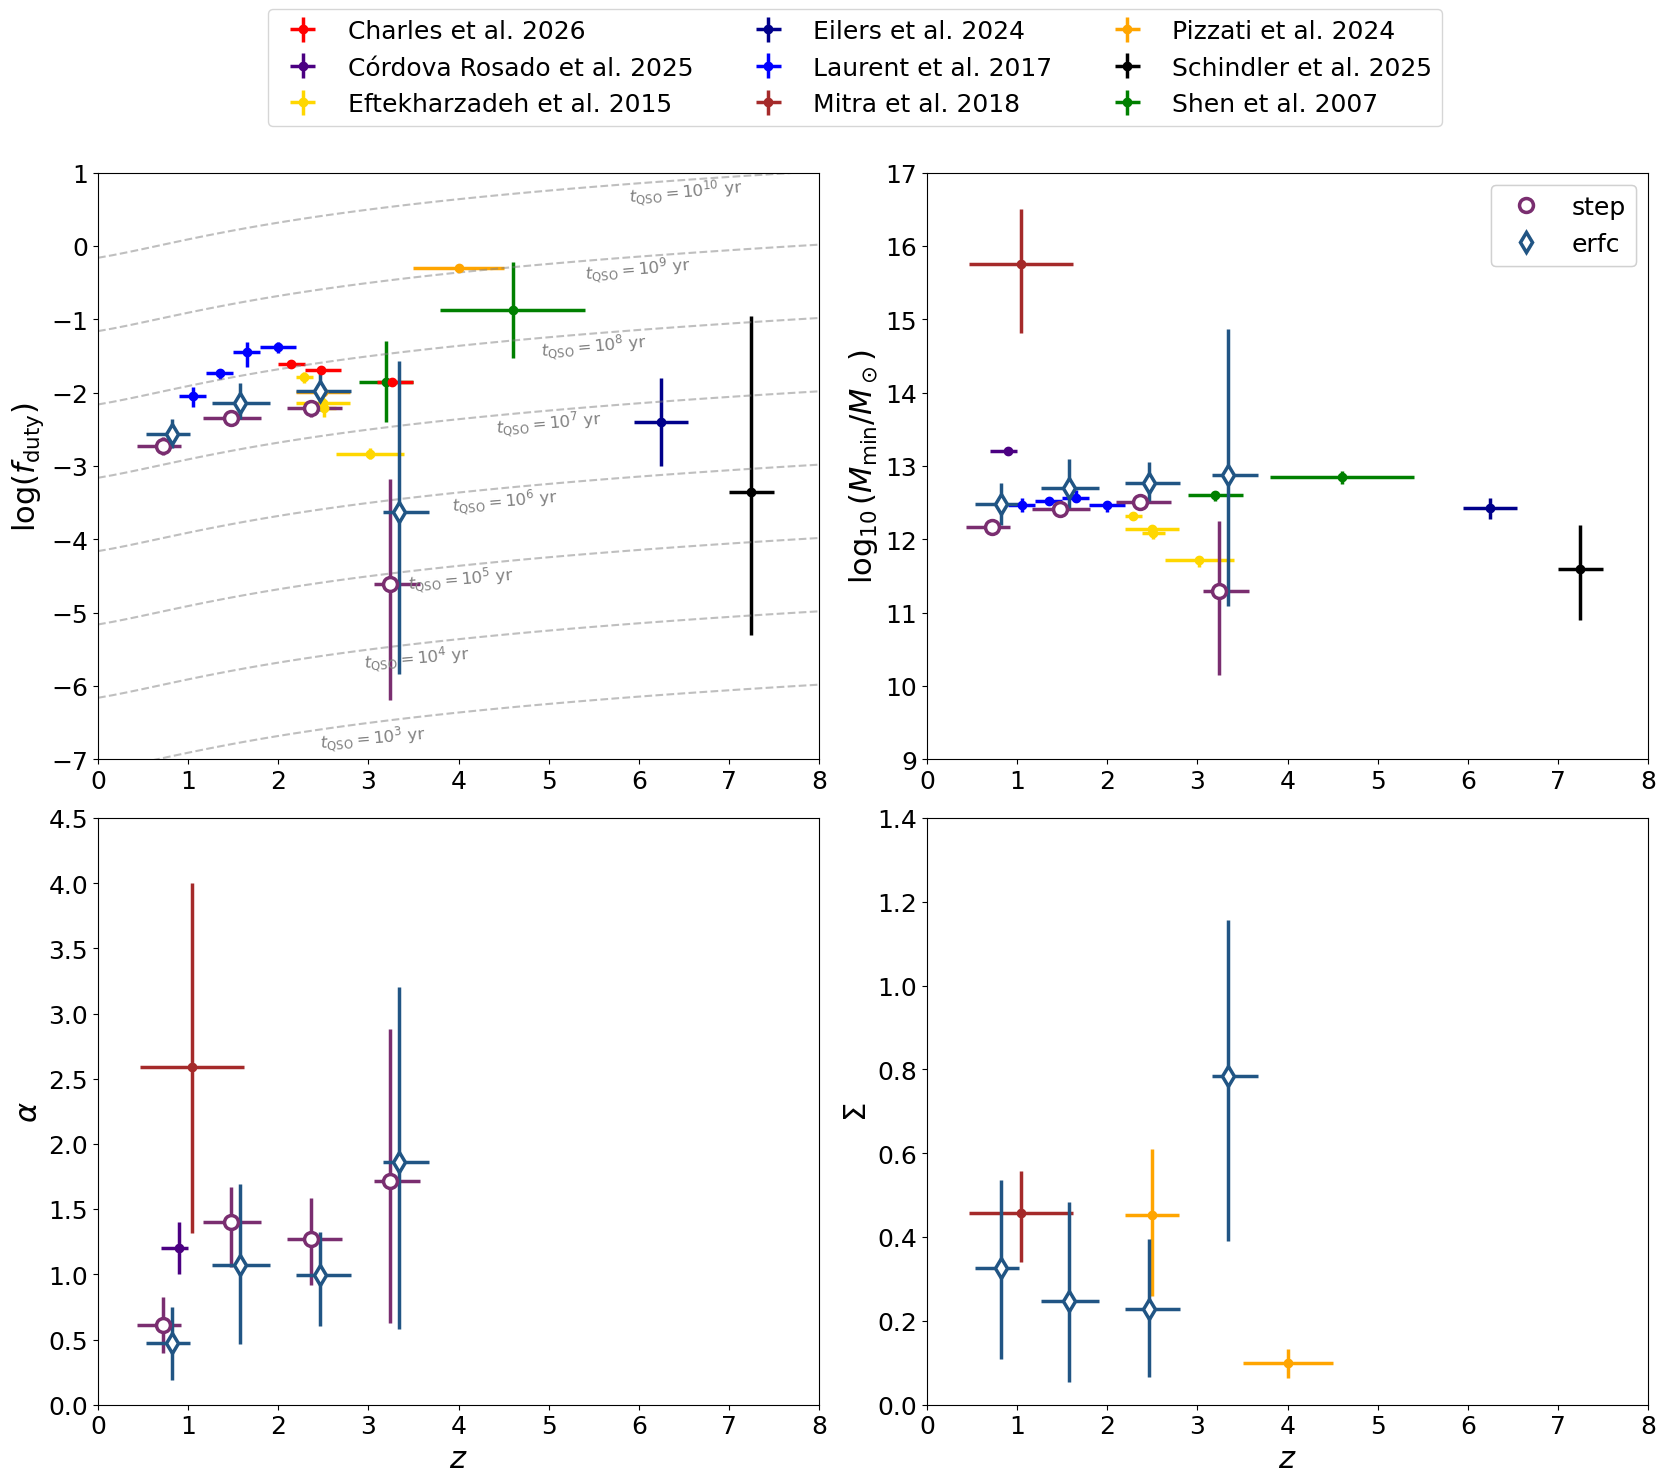

In [82]:
fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0.15, hspace = 0.1)

i = 0
ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])
ax4 = fig.add_subplot(gs[3])
ax = [ax1, ax2, ax3, ax4]
    
ax2.errorbar(z_shen, Mmin_shen, yerr = [Mmin_err_lo_shen, Mmin_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007') #https://arxiv.org/abs/2403.07986 p13
ax2.errorbar(z_centers_eft, Mmin_eft, yerr = [Mmin_err_lo_eft, Mmin_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax2.errorbar(z_centers_2, Mmin_2, yerr = [Mmin_err_lo_2, Mmin_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax2.errorbar(6.25, 12.43, yerr = [[0.15], [0.13]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024')
ax2.errorbar(7.25, 11.6, yerr = [[0.7], [0.6]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 abstract
ax2.errorbar(z_cordova, Mmin_cordova, yerr = Mmin_err_cordova, linestyle = 'none', xerr = z_err_cordova, marker = 'o', 
             color = 'indigo', linewidth = 2.5, label = 'Córdova Rosado et al. 2025')
ax2.errorbar(z_mitra, Mmin_mitra, yerr = Mmin_err_mitra, linestyle = 'none', xerr = z_err_mitra, marker = 'o', 
             color = 'brown', linewidth = 2.5, label = 'Mitra et al. 2018')

ax1.errorbar(z_shen, fduty_shen, yerr = [fduty_err_lo_shen, fduty_err_hi_shen], linestyle = 'none', xerr = z_err_shen, 
             marker = 'o', color = 'green', linewidth = 2.5, label = 'Shen et al. 2007')
ax1.errorbar(z_centers_eft, fduty_eft, yerr = [fduty_err_lo_eft, fduty_err_hi_eft], linestyle = 'none', xerr = [z_err_lo_eft, z_err_hi_eft], 
             marker = 'o', color = 'gold', linewidth = 2.5, label = 'Eftekharzadeh et al. 2015')
ax1.errorbar(z_centers_2, fduty_2, yerr = [fduty_err_lo_2, fduty_err_hi_2], linestyle = 'none', xerr = [z_err_lo_2, z_err_hi_2], 
             marker = 'o', color = 'blue', linewidth = 2.5, label = 'Laurent et al. 2017')
ax1.errorbar(6.25, np.log10(0.4/100), yerr = [[np.log10(0.4/100)-np.log10((0.4-0.3)/100)], [np.log10((1.2+0.4)/100)-np.log10(0.4/100)]], linestyle = 'none', xerr = 0.3, 
             marker = 'o', color = 'darkblue', linewidth = 2.5, label = 'Eilers et al. 2024') #https://arxiv.org/abs/2403.07986 p13
ax1.errorbar(z_pizzati, fduty_pizzati, yerr = [fduty_err_lo_pizzati, fduty_err_hi_pizzati], linestyle = 'none', xerr = z_err_pizzati, 
             marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2311.17181 table 3
ax1.errorbar(7.25, -3.36, yerr = [[1.95], [2.4]], linestyle = 'none', xerr = 0.25, 
             marker = 'o', color = 'black', linewidth = 2.5, label = 'Schindler et al. 2025') #https://arxiv.org/abs/2510.08455 sec. 4.4
ax1.errorbar(z_charles, fduty_charles, yerr = [fduty_err_lo_charles, fduty_err_hi_charles], linestyle = 'none', xerr = [z_err_lo_charles, z_err_hi_charles], 
             marker = 'o', color = 'red', linewidth = 2.5, label = 'Charles et al. 2026') #https://arxiv.org/abs/2606.27115 table 2

ax3.errorbar(z_cordova, alpha_cordova, yerr = alpha_err_cordova, linestyle = 'none', xerr = z_err_cordova, marker = 'o', 
             color = 'indigo', linewidth = 2.5, label = 'Córdova Rosado et al. 2025')
ax3.errorbar(z_mitra, alpha_mitra, yerr = alpha_err_mitra, linestyle = 'none', xerr = z_err_mitra, marker = 'o', 
             color = 'brown', linewidth = 2.5, label = 'Mitra et al. 2018')
ax3.set_xlabel('$z$')

ax4.errorbar(z_pizzati, Sigma_pizzati, yerr = Sigma_err_pizzati, linestyle = 'none', xerr = z_err_pizzati, 
             marker = 'o', color = 'orange', linewidth = 2.5, label = 'Pizzati et al. 2024') #https://arxiv.org/abs/2606.27115 table 2
ax4.errorbar(z_mitra, Sigma_mitra, yerr = Sigma_err_mitra, linestyle = 'none', xerr = z_err_mitra, marker = 'o', 
             color = 'brown', linewidth = 2.5, label = 'Mitra et al. 2018')
ax4.set_xlabel('$z$')

d = 3
start = 15
z_linspace = np.linspace(0,8)
for k, t in enumerate([1e3,1e4,1e5, 1e6, 1e7, 1e8, 1e9, 1e10]):
    fduty_linspace = t*u.yr/(1/Planck18.H(z_linspace)).to('yr')
    ax1.plot(z_linspace, np.log10(fduty_linspace), color = 'grey', alpha = 0.5, linestyle = '--')

    ax1.text(z_linspace[start:][::d][k], np.log10(fduty_linspace)[start:][::d][k]-0.25, 
                r'$t_{\rm QSO} = 10^{%d}$ yr' % int(np.log10(t)), color='grey', fontsize = 12, rotation = 5,)

legend_handles, legend_labels = [], []
for j in range(len(z_array)):
    
    a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(
                                    G_hi, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b)))
    zbin = 1/a-1
    xerr = [[zbin-np.array(z_sigma[L_bins[i]])[:,0][j]], [np.array(z_sigma[L_bins[i]])[:,1][j]-zbin]]

    for k, ndim in enumerate(ndim_array):
                
        for m, (lo, mid, hi) in enumerate(quantiles[ndim][L_bins[i]][j]):
            ax[m].errorbar(zbin+k*0.1, mid, yerr = [[mid-lo], [hi-mid]], xerr = xerr, linestyle = 'none', marker = marker[k], color = cmaps[k][i], linewidth = 2.5, markeredgewidth = 2.5, markerfacecolor = 'white', markersize = 10)
            ax[m].set_ylabel(labels[m])
            ax[m].set_xlim(0, 8)
            
            h, l = ax[m].get_legend_handles_labels()
            legend_handles.extend(h)
            legend_labels.extend(l)
            
label, ind = np.unique(legend_labels, return_index = True)
ax1.legend([legend_handles[i] for i in ind], label, ncol=3, loc='upper center', bbox_to_anchor=(1.05, 1.3))

custom_lines = [Line2D([0], [0], color = cmaps[l][i], linestyle = 'None', marker = marker[l], markeredgewidth = 2.5, markersize = 10, linewidth = 2.5, markerfacecolor = 'white') for l in range(len(ndim_array))]
second_legend = ax2.legend(custom_lines, ['step', 'erfc'])#, title = 'Shiferaw et al. 2026 (this work)', title_fontsize = 18)
fig.add_artist(second_legend)

ax1.set_ylim(-7,1)
ax2.set_ylim(9,17)
ax3.set_ylim(0, 4.5)
ax4.set_ylim(0, 1.4)

plt.savefig('../figures/constraints_step_erfc.pdf', bbox_inches = 'tight')
plt.show()

# Null test

In [83]:
C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                        G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))

In [84]:
ix_grid = np.ix_(theta_mask, theta_mask)

In [85]:
a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
                                                                                  cosmo, b)))

In [86]:
k = 1
ndim = 3
j = 3
i = 3
chi2(j, i, ndim, dlogz, nlive, log_thetamin = log_thetamin, nbins_mask = nbins_mask, Sigma = Sigma[k], 
                               a = a, theta_mask = theta_mask)

/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:166: RuntimeWarning: invalid value encountered in power
  n_m = fduty*((bins_m-M0)/M1)**alpha


[[-5.81351827 -3.48296915 -1.31498488]
 [11.26206944 13.09675863 15.01309374]
 [ 0.58957717  1.8518656   3.20665239]
 [ 0.4405614   0.79470097  1.15640942]]


(24.602940958757337,
 array([-3.48296915, 13.09675863,  1.8518656 ,  0.79470097]))

In [87]:
f0_GLS_solve([-3.46780129, 13.09675863,  1.8518656 ,  0.79470097], a, C, wp_zbin_i, H0_c_dN_dz_norm[L_bins[i]][j], ndim)

41.132248160626915

In [88]:
nbins_mask

22

In [89]:
chi2_L_z = {ndim: [] for ndim in ndim_array}
df_L_z = {}
for k, ndim in enumerate(ndim_array):

    print('ndim: {}'.format(ndim))
    df_L_z[ndim] = nbins_mask-ndim #-1

    for i in range(len(L_bins)):
    
        print('M_i<={}'.format(L_bins[i]))
    
        chi2_z=[]
        
        for j in z_array:
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
            
                print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))
                
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                        G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))
                if diag == True:
                    C*=np.identity(len(C))

                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
                                                                                  cosmo, b)))
                
                chi_2, x = chi2(j, i, ndim, dlogz, nlive, log_thetamin = log_thetamin, nbins_mask = nbins_mask, Sigma = Sigma[k], 
                               a = a, theta_mask = theta_mask)
            
                print('           chi^2: {:.2f}'.format(chi_2))
                print('   reduced chi^2: {:.2f}'.format(chi_2/df_L_z[ndim]))
                print('         delta n: {:.2e}'.format(constraint(x, a, n_q[L_bins[i]][j]))) #, fduty = f_duty[L_bins[i]][j])))
                try:
                    print('condition number: {:.2f}'.format(np.linalg.cond(C[ix_grid])))
                except Exception as e:
                    print(e)
                print('             PTE: {:.2f}\n'.format(stats.chi2.sf(chi_2, df_L_z[ndim])))
    
            else:
                chi_2=np.nan
    
            chi2_z.append(chi_2)
            
        chi2_L_z[ndim].append(chi2_z)

ndim: 2
M_i<=-20.0
0.0<z<=1.0


/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/sampler.py:147: RuntimeWarning: divide by zero encountered in divide
  return fduty/2*special.erfc(np.log(10**M_min/bins)/(np.sqrt(2)*np.log(10)*sigma))


[[-2.84236931 -2.72636096 -2.60615004]
 [12.07265009 12.1747504  12.28182419]
 [ 0.39365098  0.61190528  0.82761226]]
           chi^2: 49.53
   reduced chi^2: 2.48
         delta n: 2.64e-02
condition number: 1559678.57
             PTE: 0.00

1.0<z<=2.0
[[-2.45238587 -2.34022075 -2.24467248]
 [12.32994378 12.42065887 12.50303763]
 [ 1.05837718  1.40077738  1.66728631]]
           chi^2: 166.67
   reduced chi^2: 8.33
         delta n: 2.82e-02
condition number: 1766017.03
             PTE: 0.00

M_i<=-25.0
0.0<z<=1.0
[[-3.13734332 -2.63695456 -1.92419348]
 [12.39664459 12.76301543 13.32418083]
 [ 1.40670963  2.13283878  2.73331896]]
           chi^2: 29.00
   reduced chi^2: 1.45
         delta n: -7.66e-02
condition number: 6492632.87
             PTE: 0.09

1.0<z<=2.0
[[-2.70475612 -2.52829516 -2.33605089]
 [12.21976646 12.34883193 12.47774023]
 [ 1.7902268   1.86971436  1.95095108]]
           chi^2: 37.83
   reduced chi^2: 1.89
         delta n: 7.66e-03
condition number: 2024582.0

KeyboardInterrupt: 

In [ ]:
chi2_null = {ndim: [] for ndim in ndim_array}
df_null = nbins_mask #-1
for k, ndim in enumerate(ndim_array):

    print('ndim: {}'.format(ndim))

    for i in range(len(L_bins)):
    
        print('M_i<={}'.format(L_bins[i]))
    
        chi2_z=[]
        
        for j in z_array:
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
            
                print('{:.1f}<z<={:.1f}'.format(z_bins[j], z_bins[j+1]))
                
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                        G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))
                if diag == True:
                    C*=np.identity(len(C))

                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_bins[i], 
                                                                                  cosmo, b)))
                
                chi_2, x = chi2(j, i, ndim, dlogz, nlive, log_thetamin = log_thetamin, nbins_mask = nbins_mask, Sigma = Sigma[k], 
                               a = a, i_null = 0, theta_mask = theta_mask)
            
                print('           chi^2: {:.2f}'.format(chi_2))
                print('   reduced chi^2: {:.2f}'.format(chi_2/df_null))
                print('         delta n: {:.2e}'.format(constraint(x, a, n_q[L_bins[i]][j]))) #, fduty = f_duty[L_bins[i]][j])))
                try:
                    print('condition number: {:.2f}'.format(np.linalg.cond(C[ix_grid])))
                except Exception as e:
                    print(e)
                print('             PTE: {:.2f}\n'.format(stats.chi2.sf(chi_2, df_null)))
    
            else:
                chi_2=np.nan
    
            chi2_z.append(chi_2)
            
        chi2_null[ndim].append(chi2_z)

In [ ]:
L_array = np.array([-32, -27, -26, -25, -20])[::-1]

In [ ]:
chi2_delta = {}
for k, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (10, 8))
    gs = gridspec.GridSpec(1, 1)
    ax1 = fig.add_subplot(gs[0])

    chi2_delta[ndim] = chi2_null[ndim]-np.array(chi2_L_z[ndim])
    image = plt.pcolormesh(chi2_delta[ndim])
    
    fig.colorbar(image, label = '$\Delta\chi^2$')
    ax1.set_xticks(range(len(z_bins)), labels = z_bins)
    ax1.set_yticks(quaia.recenter(np.array(range(len(L_array)))), labels = L_bins)
    ax1.set_xlabel('$z$')
    ax1.set_ylabel('$M_{i,\mathrm{max}}$')
    plt.show()

In [ ]:
cmap_chi2 = sns.color_palette("vlag", as_cmap=True)

In [ ]:
cmap_chi2.set_bad('lightgray')

In [ ]:
cmap_M_min = sns.color_palette("vlag", n_colors = len(bins_m))
palette_M_min = matplotlib.colors.ListedColormap(cmap_M_min)
palette_M_min

In [ ]:
fig = plt.figure(figsize = (17.2, 8))
gs = gridspec.GridSpec(1, 5, wspace = 0.05, width_ratios = [1, 0.05, 1, 0.05, 0.05])
titles = ['step', 'erfc']

eps = 1e-8  # tolerance — anything below this is "zero" for your purposes
vlim = []
n_sigma_delta={}
for k, ndim in enumerate(ndim_array):

    chi2_delta_clean = np.where(np.abs(chi2_delta[ndim]) < eps, 0.0, chi2_delta[ndim])

    p_value = stats.chi2.sf(chi2_delta_clean, df_null-df_L_z[ndim])
    n_sigma_delta[ndim] = stats.norm.isf(p_value)

    vlim.append(max(np.max(n_sigma_delta[ndim][np.isfinite(n_sigma_delta[ndim])]), 
                    np.min(np.abs(n_sigma_delta[ndim][np.isfinite(n_sigma_delta[ndim])]))))

for k, ndim in enumerate(ndim_array):

    ax1 = fig.add_subplot(gs[k+k])

    image = ax1.pcolormesh(n_sigma_delta[ndim], vmin = -np.max(vlim), vmax = np.max(vlim), cmap = cmap_chi2)
    
    nan_overlay = np.where(np.isnan(n_sigma_delta[ndim]), 1.0, np.nan)
    ax1.pcolormesh(nan_overlay, cmap=plt.cm.colors.ListedColormap(['black']), vmin=0, vmax=1)
    
    ax1.set_xticks(range(len(z_bins)), labels = z_bins)
    ax1.set_yticks(quaia.recenter(np.array(range(len(L_array)))), labels = L_bins)
    ax1.set_xlabel('$z$')
    if k == 0:
        ax1.set_ylabel('$M_{i,\mathrm{max}}$')
    else:
        ax1.set_yticklabels([])
    ax1.set_title(titles[k])

fig.colorbar(image, label = '$N\sigma$', cax = fig.add_subplot(gs[-1]))

custom_lines = [mpatches.Patch(color=cmap_M_min[-1]), mpatches.Patch(color=cmap_M_min[0]), mpatches.Patch(color='lightgray'), 
                mpatches.Patch(color='black')]
first_legend = plt.legend(custom_lines, [r'yes', 'no', 'identical to null model', 
                                         'bins excluded from analysis'], bbox_to_anchor=(-0.5, -0.6, -0.75, 0.5), ncol =4)
fig.add_artist(first_legend)

# plt.suptitle('Is adding a free $M_{min}$ parameter worth it?', fontsize = 20)
plt.suptitle('Is adding luminosity dependence worth it?', fontsize = 20)
plt.savefig('../figures/null_test_step_erfc.pdf', bbox_inches = 'tight')
plt.show()

## Best-fit HOD model

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (43.75, 35))
    gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

    for j in range(len(z_array)):
        
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[j*4+i])

                label = r'$\langle N(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1],
                    quantiles[ndim][L_bins[i]][j][:,1][2])

                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim, 
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                    sigma =  r', \Sigma={:.2f}$ dex$)\rangle$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                    sigma =  r')\rangle$'
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1], 
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 5, linestyle = '-', label = label+sigma, color = cmaps[l][i])
                ax1.plot(np.log10(bins_m), n_c, linewidth = 5, linestyle = '--', color = cmaps[l][i])
                ax1.plot(np.log10(bins_m), n_s, linewidth = 5, linestyle = ':', color = cmaps[l][i])

                if j==0 or ((j == 1) and  (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                ax1.set_yscale('log')
                ax1.set_xlim(9, M_max)
                ax1.set_ylim(2e-7, 2e1)
                
                if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel(r'$\langle N(M) \rangle_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
                else:
                    ax1.set_yticks([])
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel('$\log_{10} (M/M_\odot)$')
                
                ax1.legend()
                
    custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 5), 
                    Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 5), 
                    Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 5)]
    first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
                                             r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
                              bbox_to_anchor=(0.0, 0.0), loc = 'lower right')
    fig.add_artist(first_legend)

    plt.savefig('../figures/HOD_ndim{}.pdf'.format(ndim), bbox_inches = 'tight')
    plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (43.75, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            ax1 = fig.add_subplot(gs[j*4+i])

            for l, ndim in enumerate(ndim_array):

                label = r'$\langle N(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
                
                if ndim == 3:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim,
                                    sigma = quantiles[ndim][L_bins[i]][j][:,1][3])
                    sigma =  r', \Sigma={:.2f}$ dex$)\rangle$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    n_c=sampler.N_c(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], 10**quantiles[ndim][L_bins[i]][j][:,1][0], ndim)
                    sigma =  r')\rangle$'
                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1],
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
    
                ax1.plot(np.log10(bins_m), n_c+n_s, linewidth = 5, linestyle = '-', label = label+sigma, color = cmaps[l][i])
                ax1.plot(np.log10(bins_m), n_c, linewidth = 2.5, linestyle = '--', color = cmaps[l][i])
                ax1.plot(np.log10(bins_m), n_s, linewidth = 2.5, linestyle = ':', color = cmaps[l][i])

                if j==0 or ((j == 1) and  (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                ax1.set_yscale('log')
                ax1.set_xlim(9, M_max)
                ax1.set_ylim(2e-7, 2e1)
                
                if i==0 or ((j>1) and (i <3) and (i!=j)):
                    ax1.set_ylabel(r'$\langle N(M) \rangle_{{{:.1f}<z \leq{:.1f}}}$'.format(z_bins[j], z_bins[j+1]))
                else:
                    ax1.set_yticks([])
                if j > 2 or ((j>0) and (i <2) and (i!=j)):
                    ax1.set_xlabel('$\log_{10} (M/M_\odot)$')
                
            ax1.legend()

custom_lines = [Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = '--', linewidth = 2.5), 
                    Line2D([0], [0], color = 'black', linestyle = ':', linewidth = 2.5)]
first_legend = fig.legend(custom_lines, [r'$\langle N(M) \rangle = \langle N_c(M) \rangle +\langle N_s(M) \rangle$', 
                                         r'$\langle N_c(M) \rangle$', r'$\langle N_s(M) \rangle$'], bbox_transform=ax1.transAxes, 
                              bbox_to_anchor=(1.0, 1.0), loc = 'upper right')
fig.add_artist(first_legend)

plt.savefig('../figures/HOD_step_erfc.pdf'.format(ndim), bbox_inches = 'tight')
plt.show()

# Plot the fit to the model

In [ ]:
delta_xlim = np.diff(np.log10(thetabins))[0]/2
delta_xlim/2, thetabins, 10**(np.log10(thetabins) - 2*delta_xlim)

In [ ]:
wp_2h_16, wp_2h_50, wp_2h_84 = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}, {ndim: {L: [] for L in L_bins} for ndim in ndim_array}, {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
for l, ndim in enumerate(ndim_array):
    
    # remove bottom panel and just print bq somewhere
    # plot!
    for j in range(len(z_array)):
        
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
                if ndim == 3:
                    sigma = equal_weight_samples[ndim][L_bins[i]][j][:,-1]
                    label_Sigma= ''
                else:
                    sigma = np.zeros(np.shape(equal_weight_samples[ndim][L_bins[i]][j][:,-1]))
                    label_Sigma = '_Sigma0.0'

                file = '_zmin{}zmax{}_Lmax{}_ndim{}{}'.format(z_bins[j], z_bins[j+1], L_bins[i], ndim, label_Sigma) 

                try:

                    w_mean = np.load('../results/results_wtheta_mean{}_1000.npy'.format(file))
                    w_2h_16 = np.load('../results/results_wtheta_16{}_1000.npy'.format(file))
                    w_2h_84 = np.load('../results/results_wtheta_84{}_1000.npy'.format(file))

                except:

                    ind = rng.choice(range(len(equal_weight_samples[ndim][L_bins[i]][j])), size = 1000, replace = False)
                
                    wp_2h_samples=[]
                    for k in ind:
                        # n_m=np.ones(np.shape(bins_m))*10**equal_weight_samples[ndim][L_bins[i]][j][:,0][k]
                        wp_2h_sample = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [equal_weight_samples[ndim][L_bins[i]][j][:,0][k], equal_weight_samples[ndim][L_bins[i]][j][:,1][k], sigma[k], np.log10(12*10**equal_weight_samples[ndim][L_bins[i]][j][:,1][k]), 
                                                                                                         equal_weight_samples[ndim][L_bins[i]][j][:,2][k]], ndim, recenter_thetabins = False)
                                                                 # theta_mask = theta_mask)
                        wp_2h_samples.append(wp_2h_sample)
                    w_2h_16, w_2h_50, w_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

                    w_mean = np.mean(wp_2h_samples, axis = 0)

                    np.save('../results/results_wtheta_mean{}_1000.npy'.format(file), w_mean)
                    np.save('../results/results_wtheta_16{}_1000.npy'.format(file), w_2h_16)
                    np.save('../results/results_wtheta_84{}_1000.npy'.format(file), w_2h_84)

                wp_2h_50[ndim][L_bins[i]].append(w_mean)
                wp_2h_16[ndim][L_bins[i]].append(w_2h_16)
                wp_2h_84[ndim][L_bins[i]].append(w_2h_84)
                
            else:
                wp_2h_50[ndim][L_bins[i]].append(np.nan)
                wp_2h_16[ndim][L_bins[i]].append(np.nan)
                wp_2h_84[ndim][L_bins[i]].append(np.nan)

In [ ]:
xlim = 10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim) 
ylim = 1e-5, 2e2
y = np.linspace(ylim[0], ylim[-1])
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (20, 16))
    gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
    
    # remove bottom panel and just print bq somewhere
    # plot!
    for j in range(len(z_array)):
    
        ax1 = fig.add_subplot(gs[j])
    
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))

                # print(i, j, 'plotting data')
                ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = cmap_theta[i], yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')

                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, color = cmap_theta[i]) #, label = '$M_i\leq{}$'.format(L_bins[i]))
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmap_theta[i])
            
        if quaia.recenter(thetabins)[-1] > 1:
            ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                          alpha = 0.25, label = 'scales excluded from fit')
            ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                              alpha = 0.25)

        ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))

        ax1.set_xlim(xlim)
        ax1.set_ylim(ylim)

        ax1.set_xscale('log')
        ax1.set_yscale('log')
        
        if j%2==0:
            ax1.set_ylabel(r'$w(\theta)$')
        else:
            ax1.set_yticks([])
        if j > 1:
            ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

    # h, l = ax1.get_legend_handles_labels()
    # label, ind = np.unique(l, return_index = True)
    # ax1.legend([h[i] for i in ind], label)
    # ax1.legend()

    custom_lines = [mpatches.Patch(color=cmap_theta[l]) for l in range(len(L_bins))]
    # custom_lines = [Line2D([0], [0], color = cmap_theta[l], linestyle = '-', linewidth = 2.5) for l in range(len(L_bins))]
    first_legend = fig.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))], loc = 'lower left', bbox_transform=ax1.transAxes, 
                              bbox_to_anchor=(0.0, 0.0))
    fig.add_artist(first_legend)

    custom_lines = [Line2D([0], [0], color = 'black', linestyle = 'None', marker = 'o', linewidth = 2.5, markeredgewidth = 2.5),
                Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), mpatches.Patch(color='grey', alpha = 0.5)]
    second_legend = ax1.legend(custom_lines, [r'Quaia', r'Shiferaw et al. 2026 (this work)', 'scales excluded from fit'], loc = 'upper right')
    fig.add_artist(second_legend)

    plt.show()

In [ ]:
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (20, 16))
    gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
    
    # remove bottom panel and just print bq somewhere
    # plot!
    for i in range(len(L_bins)):
        
        ax1 = fig.add_subplot(gs[i])

        for j in range(len(z_array)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                
                ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + j*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = cmap_theta[j], yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
    
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, color = cmap_theta[j])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmap_theta[j])

        if quaia.recenter(thetabins)[-1] > 1:
            ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                          alpha = 0.25, label = 'scales excluded from fit')
            ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                              alpha = 0.25)
            
        ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))

        ax1.set_xlim(xlim)
        ax1.set_ylim(ylim)

        ax1.set_xscale('log')
        ax1.set_yscale('log')
        
        if i%2==0:
            ax1.set_ylabel(r'$w(\theta)$')
        else:
            ax1.set_yticks([])
        if i > 1:
            ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
            
    custom_lines = [mpatches.Patch(color=cmap_theta[l]) for l in range(len(L_bins))]
    first_legend = fig.legend(custom_lines, [r'${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]) for j in range(len(z_array))], loc = 'lower left', bbox_transform=ax1.transAxes, bbox_to_anchor=(0.0, 0.0))
    fig.add_artist(first_legend)

    custom_lines = [Line2D([0], [0], color = 'black', linestyle = 'None', marker = 'o', linewidth = 2.5, markeredgewidth = 2.5),
                Line2D([0], [0], color = 'black', linestyle = '-', linewidth = 2.5), mpatches.Patch(color='grey', alpha = 0.5)]
    second_legend = ax1.legend(custom_lines, [r'Quaia', r'Shiferaw et al. 2026 (this work)', 'scales excluded from fit'], loc = 'upper right')
    fig.add_artist(second_legend)
    
    plt.show()

In [ ]:
cmap_grey = plt.get_cmap('Greys')(np.linspace(0.333, 0.999, len(L_bins)))

In [ ]:
xlim = 10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim) 
ylim = 1e-5, 2e2
y = np.linspace(ylim[0], ylim[-1])

fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
    
# remove bottom panel and just print bq somewhere
# plot!
for j in range(len(z_array)):

    ax1 = fig.add_subplot(gs[j])

    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            for l, ndim in enumerate(ndim_array):

                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))

                ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + i*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = cmap_grey[::-1][i], yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')

                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, color = cmaps[l][i]) #, label = '$M_i\leq{}$'.format(L_bins[i]))
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmaps[l][i])
            
    if quaia.recenter(thetabins)[-1] > 1:
        ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                      alpha = 0.25, label = 'scales excluded from fit')
        ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                          alpha = 0.25)

    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))

    ax1.set_xlim(xlim)
    ax1.set_ylim(ylim)

    ax1.set_xscale('log')
    ax1.set_yscale('log')
    
    if j%2==0:
        ax1.set_ylabel(r'$w(\theta)$')
    else:
        ax1.set_yticks([])
    if j > 1:
        ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

    custom_lines = [mpatches.Patch(color=cmap_grey[::-1][l]) for l in range(len(L_bins))]
    first_legend = fig.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))], loc = 'lower left', bbox_transform=ax1.transAxes, 
                              bbox_to_anchor=(0.0, 0.0))
    fig.add_artist(first_legend)

    custom_lines = [Line2D([0], [0], color = np.mean(cmap_grey[::-1], axis = 0), linestyle = 'None', marker = 'o', linewidth = 2.5, markeredgewidth = 2.5),
                Line2D([0], [0], color = np.mean(cmap_theta, axis = 0), linestyle = '-', linewidth = 2.5), Line2D([0], [0], color = np.mean(cmap, axis = 0), linestyle = '-', linewidth = 2.5), mpatches.Patch(color='grey', alpha = 0.5)]
    second_legend = ax1.legend(custom_lines, [r'Quaia', r'step', 'erfc', 'scales excluded from fit'], loc = 'upper right')
    fig.add_artist(second_legend)

plt.show()

In [ ]:
xlim = 10**(np.log10(quaia.recenter(thetabins))[0] - delta_xlim), 10**(np.log10(quaia.recenter(thetabins))[-1] + 5/2*delta_xlim) 
ylim = 1e-5, 2e2
y = np.linspace(ylim[0], ylim[-1])

fig = plt.figure(figsize = (20, 16))
gs = gridspec.GridSpec(2, 2, wspace = 0, hspace = 0.15)
    
# remove bottom panel and just print bq somewhere
# plot!
for i in range(len(L_bins)):

    ax1 = fig.add_subplot(gs[i])

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):

            for l, ndim in enumerate(ndim_array):

                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))

                ax1.errorbar(10**(np.log10(quaia.recenter(thetabins)) + j*delta_xlim/2), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = cmap_grey[::-1][j], yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')

                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, color = cmaps[l][j]) #, label = '$M_i\leq{}$'.format(L_bins[i]))
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmaps[l][j])
            
    if quaia.recenter(thetabins)[-1] > 1:
        ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                      alpha = 0.25, label = 'scales excluded from fit')
        ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                          alpha = 0.25)

    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))

    ax1.set_xlim(xlim)
    ax1.set_ylim(ylim)

    ax1.set_xscale('log')
    ax1.set_yscale('log')
    
    if i%2==0:
        ax1.set_ylabel(r'$w(\theta)$')
    else:
        ax1.set_yticks([])
    if i > 1:
        ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected

    custom_lines = [mpatches.Patch(color=cmap_grey[::-1][l]) for l in range(len(L_bins))]
    first_legend = fig.legend(custom_lines, [r'$M_i\leq{}$'.format(L_bins[i]) for i in range(len(L_bins))], loc = 'lower left', bbox_transform=ax1.transAxes, 
                              bbox_to_anchor=(0.0, 0.0))
    fig.add_artist(first_legend)

    custom_lines = [Line2D([0], [0], color = np.mean(cmap_grey[::-1], axis = 0), linestyle = 'None', marker = 'o', linewidth = 2.5, markeredgewidth = 2.5),
                Line2D([0], [0], color = np.mean(cmap_theta, axis = 0), linestyle = '-', linewidth = 2.5), Line2D([0], [0], color = np.mean(cmap, axis = 0), linestyle = '-', linewidth = 2.5), mpatches.Patch(color='grey', alpha = 0.5)]
    second_legend = ax1.legend(custom_lines, [r'Quaia', r'step', 'erfc', 'scales excluded from fit'], loc = 'upper right')
    fig.add_artist(second_legend)

plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (43.75, 35))
    gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
    
    for j in range(len(z_array)):
        
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[j*4+i])

                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])

                if ndim == 3:
                    label_sigma =  r', \Sigma={:.2f}$ dex$)$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    label_sigma =  r')$'
                    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                
                ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
                
                if quaia.recenter(thetabins)[-1] > 1:
                    ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                                  alpha = 0.25, label = 'scales excluded from fit')
                    ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                      alpha = 0.25)
    
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, label = label + label_sigma, color = cmaps[l][i])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmaps[l][i])
                
                if j==0 or ((j == 1) and (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                ax1.set_xlim(xlim)
                ax1.set_ylim(ylim)

                ax1.set_xscale('log')
                ax1.set_yscale('log')
                
                if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
                else:
                    ax1.set_yticklabels([])
            
                if j > 2 or ((j>0) and (i<2) and (i!=j)):
                    ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
                    
                ax1.legend()

    plt.savefig('../figures/fit_ndim{}.pdf'.format(ndim), bbox_inches = 'tight')
    plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (43.75, 35))
    gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
            
    for i in range(len(L_bins)):

        for j in range(len(z_array)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[i*4+j])

                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])

                if ndim == 3:
                    label_sigma =  r', \Sigma={:.2f}$ dex$)$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    label_sigma =  r')$'
                    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                
                ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
                
                if quaia.recenter(thetabins)[-1] > 1:
                    ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                                  alpha = 0.25, label = 'scales excluded from fit')
                    ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                      alpha = 0.25)
    
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, label = label+label_sigma, color = cmap_theta[j])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmap_theta[j])
                
                if i ==0 or ((i<3) and (j>1) and (i!=j)):
                    ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
                ax1.set_xlim(xlim)
                ax1.set_ylim(ylim)

                ax1.set_xscale('log')
                ax1.set_yscale('log')
                
                if j==0:
                    ax1.set_ylabel(r'$w_{{M_i\leq{}}}(\theta)$'.format(L_bins[i]))
                else:
                    ax1.set_yticklabels([])
            
                if i > 2 or ((i == 2) and (j == 0)):
                    ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
                    
                ax1.legend()

    plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (43.75, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)

for j in range(len(z_array)):
    
    for i in range(len(L_bins)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
            ax1 = fig.add_subplot(gs[j*4+i])

            for l, ndim in enumerate(ndim_array):

                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])

                if ndim == 3:
                    label_sigma =  r', \Sigma={:.2f}$ dex$)$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    label_sigma =  r')$'

                n_s = sampler.N_s(bins_m, 10**quantiles[ndim][L_bins[i]][j][:,1][0], 10**quantiles[ndim][L_bins[i]][j][:,1][1],
                                  12*10**quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][2])
                
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
    
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, label = label+label_sigma, color = cmaps[l][i])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmaps[l][i])

            ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            
            if quaia.recenter(thetabins)[-1] > 1:
                ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                              alpha = 0.25, label = 'scales excluded from fit')
                ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                  alpha = 0.25)
                
            if j==0 or ((j == 1) and (i == 3)):
                ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
            ax1.set_xlim(xlim)
            ax1.set_ylim(ylim)

            ax1.set_xscale('log')
            ax1.set_yscale('log')
            
            if i==0 or ((j>1) and (i<3) and (i!=j)):
                ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
            else:
                ax1.set_yticklabels([])
        
            if j > 2 or ((j>0) and (i<2) and (i!=j)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
                    
            ax1.legend()

plt.show()

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
fig = plt.figure(figsize = (43.75, 35))
gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
        
for i in range(len(L_bins)):

    for j in range(len(z_array)):

        if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
            ax1 = fig.add_subplot(gs[i*4+j])

            for l, ndim in enumerate(ndim_array):

                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], 
                    quantiles[ndim][L_bins[i]][j][:,1][2])
    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
    
                ax1.plot(thetabins, wp_2h_50[ndim][L_bins[i]][j], linewidth = 2.5, label = label+label_sigma, color = cmaps[l][j])
                ax1.fill_between(thetabins, wp_2h_16[ndim][L_bins[i]][j], wp_2h_84[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmaps[l][j])

            ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                         label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
            
            if quaia.recenter(thetabins)[-1] > 1:
                ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                              alpha = 0.25, label = 'scales excluded from fit')
                ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                  alpha = 0.25)
                
            if i ==0 or ((i<3) and (j>1) and (i!=j)):
                ax1.set_title('${:.1f}<z \leq{:.1f}$'.format(z_bins[j], z_bins[j+1]))
            ax1.set_xlim(xlim)
            ax1.set_ylim(ylim)

            ax1.set_xscale('log')
            ax1.set_yscale('log')
            
            if j==0:
                ax1.set_ylabel(r'$w_{{M_i\leq{}}}(\theta)$'.format(L_bins[i]))
            else:
                ax1.set_yticklabels([])
        
            if i > 2 or ((i == 2) and (j == 0)):
                ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
                    
            ax1.legend()

plt.show()

# Test a larger scale cut

In [ ]:
dlogz = 0.01
nlive = 500
log_thetamin_array = np.log10(np.logspace(-2.8, -1.2, 5))
log_thetamin = np.log10(np.logspace(-2.8, -1.2, 5))[-1]
theta_mask=(quaia.recenter(np.log10(thetabins))>=log_thetamin) & (quaia.recenter(np.log10(thetabins))<=log_thetamax)
nbins_mask = np.sum(theta_mask)

In [ ]:
quantiles_2h = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
equal_weight_samples_2h = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
for i in range(len(L_bins)):    

    for j in range(len(z_array)):

        for l, ndim in enumerate(ndim_array):

            if np.round(N_q[L_bins[i]][j]/1000)>1:

                quantiles_bin, equal_weight_samples_bin = f_duty(j, i, ndim, dlogz, nlive, Sigma = None, log_thetamin = log_thetamin, nbins_mask = nbins_mask)
                quantiles_2h[ndim][L_bins[i]].append(quantiles_bin)
                equal_weight_samples_2h[ndim][L_bins[i]].append(equal_weight_samples_bin)
                
            else:
                
                quantiles_2h[ndim][L_bins[i]].append([[np.nan]*3])
                equal_weight_samples_2h[ndim][L_bins[i]].append([np.nan]*(ndim+1))

In [ ]:
wp_2h_16_2h, wp_2h_50_2h, wp_2h_84_2h = {ndim: {L: [] for L in L_bins} for ndim in ndim_array}, {ndim: {L: [] for L in L_bins} for ndim in ndim_array}, {ndim: {L: [] for L in L_bins} for ndim in ndim_array}
for l, ndim in enumerate(ndim_array):
    
    # remove bottom panel and just print bq somewhere
    # plot!
    for j in range(len(z_array)):
        
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
                
                if ndim == 3:
                    sigma = equal_weight_samples_2h[ndim][L_bins[i]][j][:,-1]
                    label_Sigma= ''
                else:
                    sigma = np.zeros(np.shape(equal_weight_samples_2h[ndim][L_bins[i]][j][:,-1]))
                    label_Sigma = '_Sigma0.0'

                file = '_zmin{}zmax{}_Lmax{}_ndim{}{}'.format(z_bins[j], z_bins[j+1], L_bins[i], ndim, label_Sigma) 

                try:

                    w_mean = np.load('../results/results_wtheta_mean{}_dlogz{}_nlive{}_logrmin{}_1000.npy'.format(file, dlogz, nlive, log_thetamin))
                    w_2h_16 = np.load('../results/results_wtheta_16{}_dlogz{}_nlive{}_logrmin{}_1000.npy'.format(file, dlogz, nlive, log_thetamin))
                    w_2h_84 = np.load('../results/results_wtheta_84{}_dlogz{}_nlive{}_logrmin{}_1000.npy'.format(file, dlogz, nlive, log_thetamin))

                except:

                    ind = rng.choice(range(len(equal_weight_samples_2h[ndim][L_bins[i]][j])), size = 1000, replace = False)
                
                    wp_2h_samples=[]
                    for k in ind:
                        # n_m=np.ones(np.shape(bins_m))*10**equal_weight_samples[ndim][L_bins[i]][j][:,0][k]
                        wp_2h_sample = sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [equal_weight_samples_2h[ndim][L_bins[i]][j][:,0][k], equal_weight_samples_2h[ndim][L_bins[i]][j][:,1][k], sigma[k], 
                                                                                                         np.log10(12*10**equal_weight_samples_2h[ndim][L_bins[i]][j][:,1][k]), 
                                                                                                         equal_weight_samples_2h[ndim][L_bins[i]][j][:,2][k]], ndim, recenter_thetabins = False)
                                                                 # theta_mask = theta_mask)
                        wp_2h_samples.append(wp_2h_sample)
                    w_2h_16, w_2h_50, w_2h_84 = np.percentile(wp_2h_samples, [16, 50, 84], axis=0)

                    w_mean = np.mean(wp_2h_samples, axis = 0)

                    np.save('../results/results_wtheta_mean{}_dlogz{}_nlive{}_logrmin{}_1000.npy'.format(file, dlogz, nlive, log_thetamin), w_mean)
                    np.save('../results/results_wtheta_16{}_dlogz{}_nlive{}_logrmin{}_1000.npy'.format(file, dlogz, nlive, log_thetamin), w_2h_16)
                    np.save('../results/results_wtheta_84{}_dlogz{}_nlive{}_logrmin{}_1000.npy'.format(file, dlogz, nlive, log_thetamin), w_2h_84)

                wp_2h_50_2h[ndim][L_bins[i]].append(w_mean)
                wp_2h_16_2h[ndim][L_bins[i]].append(w_2h_16)
                wp_2h_84_2h[ndim][L_bins[i]].append(w_2h_84)
                
            else:
                wp_2h_50_2h[ndim][L_bins[i]].append(np.nan)
                wp_2h_16_2h[ndim][L_bins[i]].append(np.nan)
                wp_2h_84_2h[ndim][L_bins[i]].append(np.nan)

In [ ]:
# remove bottom panel and just print bq somewhere
# plot!
for l, ndim in enumerate(ndim_array):

    fig = plt.figure(figsize = (43.75, 35))
    gs = gridspec.GridSpec(4, 4, wspace = 0, hspace = 0.1)
    
    for j in range(len(z_array)):
        
        for i in range(len(L_bins)):
    
            if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
    
                ax1 = fig.add_subplot(gs[j*4+i])

                label = r'$w_q(f_\mathrm{{duty}}=10^{{{:.2f}}}, M_\mathrm{{min}}=10^{{{:.2f}}}M_\odot, \alpha={:.2f}'.format(
                        quantiles_2h[ndim][L_bins[i]][j][:,1][0], quantiles_2h[ndim][L_bins[i]][j][:,1][1], 
                    quantiles_2h[ndim][L_bins[i]][j][:,1][2])

                if ndim == 3:
                    label_sigma =  r', \Sigma={:.2f}$ dex$)$'.format(quantiles[ndim][L_bins[i]][j][:,1][3])
                else:
                    label_sigma =  r')$'
                    
                C = np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_N{}_{}_MC_b{}.npy'.format(
                G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))

                wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_MC_b{}.npy'.format(G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                
                ax1.errorbar(quaia.recenter(thetabins), wp_zbin_i, linewidth = 2.5, marker = 'd', 
                             label = r'Quaia', color = 'black', yerr = np.sqrt(np.diag(C)), markeredgewidth = 2.5, linestyle = 'none')
                
                if quaia.recenter(thetabins)[-1] > 1:
                    ax1.fill_betweenx(y, x1 = xlim[0], x2 = 10**log_thetamin, color = 'grey', 
                                  alpha = 0.25, label = 'scales excluded from fit')
                    ax1.fill_betweenx(y, x1 = 1, x2 = xlim[-1], color = 'grey', 
                                      alpha = 0.25)
    
                ax1.plot(thetabins, wp_2h_50_2h[ndim][L_bins[i]][j], linewidth = 2.5, label = label + label_sigma, color = cmaps[l][i])
                ax1.fill_between(thetabins, wp_2h_16_2h[ndim][L_bins[i]][j], wp_2h_84_2h[ndim][L_bins[i]][j], linewidth = 2.5, alpha = 0.5, color = cmaps[l][i])
                
                if j==0 or ((j == 1) and (i == 3)):
                    ax1.set_title('$M_i\leq{}$'.format(L_bins[i]))
                ax1.set_xlim(xlim)
                ax1.set_ylim(ylim)

                ax1.set_xscale('log')
                ax1.set_yscale('log')
                
                if i==0 or ((j>1) and (i<3) and (i!=j)):
                    ax1.set_ylabel(r"$w_{{{:.1f}<z \leq{:.1f}}}(\theta)$".format(z_bins[j], z_bins[j+1]))
                else:
                    ax1.set_yticklabels([])
            
                if j > 2 or ((j>0) and (i<2) and (i!=j)):
                    ax1.set_xlabel(r'$\theta$ $[^\circ]$') # projected
                    
                ax1.legend()

    plt.savefig('../figures/fit_ndim{}_conservative.pdf'.format(ndim), bbox_inches = 'tight')
    plt.show()

In [ ]:
ylabels = ['\log_{10}(M_{min}/M_\odot)', r'\alpha', '\Sigma']

In [ ]:
def make_contour_cmap(color, n_levels, alpha_min=0, alpha_max=1.0):
    
    cmap = []
    alphas = np.linspace(0,alpha_max,n_levels+1)
    for alpha in alphas:
        rgba = np.array(mcolors.to_rgba(color))
        rgba[-1] = alpha
        cmap.append(rgba)

    return cmap

In [ ]:
quantile_2d = 1.0 - np.exp(-0.5 * np.array([1, 2])**2)#, 3])**2)
quantile_2d

In [ ]:
smooth = [[0.04, 0.05, 0.03, 0.05], [0.09, 0.09, 0.08, 0.09]] # 0.05 # 0.08

In [ ]:
# plot!
fig = plt.figure(figsize=(60, 60))
gs = gridspec.GridSpec(4, 4, wspace=0.05, hspace=0.1)
for j in range(len(z_array)):

    for i in range(len(L_bins)):

        if (((i < 3) and (N_q[L_bins[i]][j] > N_q[L_bins[i+1]][j])) or (i == 3)) and (np.round(N_q[L_bins[i]][j]/1000) > 1):

            # carve an ndim x ndim sub-grid out of this outer cell
            sub_gs = gs[j*4+i].subgridspec(3, 3, wspace=0.0, hspace=0.0) #0.05
            ax = np.array([[fig.add_subplot(sub_gs[r, c]) for c in range(3)]
                                 for r in range(3)])

            custom_lines, legend_labels = [], []
            for k, ndim in enumerate(ndim_array[::-1]):

                try:
                    if ndim == 2:
                        # sigma='_Sigma0.0'
                        linewidth = 2.5
                        fill_contours = True
                        plot_density = True
                        no_fill_contours = True
                        zorder = 3
                    else:
                        # sigma=''
                        linewidth = 2.5
                        fill_contours = True
                        plot_density = True
                        no_fill_contours = True
                        zorder = 1
                    file = '_G{}_logrmin{:.1f}_logrmax{}_nbins{}_zmin{}zmax{}_Lmax{}_{}_ndim{}_dlogz{}_nlive{}_{}'.format(
                        G_hi, log_thetamin, log_thetamax, nbins_mask, z_bins[j], z_bins[j+1], L_bins[i], cosmo, ndim, dlogz, 
                        nlive, sample) 
                    
                    # read the results
                    with open('../results/results{}.npy'.format(file), 'rb') as fp: #_ndim{}_dlogz{}_nlive{}_{}.npy'.format(
                        results = pickle.load(fp)
    
                    samples, weights = results.samples, results.importance_weights()
    
                    contourf_kwargs = {'colors': make_contour_cmap(cmaps[::-1][k][i], len(quantile)), 'zorder': zorder}
                    contour_kwargs = {'colors': [cmaps[::-1][k][i]], 'linewidths': linewidth, 'zorder': zorder}
                    dyplot.cornerplot(results, color=cmaps[::-1][k][i], hist2d_kwargs = {
                        'contourf_kwargs': contourf_kwargs, 'contour_kwargs': contour_kwargs, 'fill_contours': fill_contours, 
                        'plot_density': plot_density, 'no_fill_contours': no_fill_contours}, max_n_ticks=3, 
                                      quantiles=[], quantiles_2d = quantile_2d, title_quantiles = quantile, labels = ['']*ndim,
                                      fig=(fig, ax[:ndim, :ndim]), smooth = smooth[::-1][k][j], hist_kwargs = {
                                          'density': True, 'histtype': 'step', 'linewidth': linewidth, 'alpha': 1})
    
                    # quantiles = [dyfunc.quantile(samples[:, k], quantile, weights=weights) 
                    #              for k in range(samples.shape[1])]

                    # # Compute weighted mean and covariance.
                    # mean, cov = dyfunc.mean_and_cov(samples, weights)
                    
                    legend=[]
                    for l, (lo, mid, hi) in enumerate(quantiles_2h[ndim][L_bins[i]][j]):

                        # mid = mean[l]
                        
                        legend.append(f"${ylabels[l]}={mid:.2f}^{{+{hi-mid:.2f}}}_{{-{mid-lo:.2f}}}$")
    
                    custom_lines.append(Line2D([0], [0], color=cmaps[::-1][k][i], linestyle='-', linewidth=linewidth))
                    if ndim == 2:
                        legend_labels.append('{}, {}'.format(legend[0], legend[1]))
                    else:
                        legend_labels.append('{}, {}, {}'.format(legend[0], legend[1], legend[2]))
                
                except Exception as e:
                    print(e)#'Unexpected error for bin (j={}, i={}): {}'.format(j, i, e))

                ax1 = ax[1, 0]
                ax1.legend(handles=custom_lines, labels=legend_labels, fontsize=8, loc='upper right')
                
                # --- axis limits/labels on the main Mmin-alpha panel ---
                ax[1, 0].set_ylim(0, 4)
                ax[1, 1].set_xlim(0, 4)
                if ndim==3:
                    ax[-1, 0].set_ylim(0, 1.4)
                    ax[-1, 1].set_ylim(0, 1.4)
                    ax[-1, 1].set_xlim(0, 4)
                    ax[-1, -1].set_xlim(0, 1.4)
    
                if j == 0 or ((j == 1) and (i == 3)):
                    ax[0, 0].set_title('$M_i\\leq{}$'.format(L_bins[i]))
                for k, axis in enumerate(ax[:, 0]):
                    axis.set_xlim(9, 16)
                    if not (i == 0 or ((j > 1) and (i < 3) and (i != j))):
                        axis.set_yticklabels([])
                    elif k>0:
                        axis.set_ylabel(r"${}_{{{:.1f}<z\leq{:.1f}}}$".format(ylabels[k], z_bins[j], z_bins[j+1]))
                for k, axis in enumerate(ax[-1, :]):
                    axis.xaxis.set_label_coords(0.5, -0.2)
                    if j > 2 or ((j > 0) and (i < 2) and (i != j)):
                        axis.set_xlabel('${}$'.format(ylabels[k]))
                    plt.setp(axis.get_xticklabels(), rotation=0, ha='center')

fig.savefig('../figures/cornerplot_conservative.pdf'.format(ndim), bbox_inches='tight')
plt.show()

# Derived HOD parameters

In [ ]:
b_q

In [ ]:
linear_mask = (quaia.recenter(thetabins)>=0.1) & (quaia.recenter(thetabins)<=1)
# remove bottom panel and just print bq somewhere
# plot!
# i = 0

for ndim in ndim_array:

    fig = plt.figure(figsize = (10, 8))
    gs = gridspec.GridSpec(1, 1, wspace = 0, hspace = 0.15)

    ax1 = fig.add_subplot(gs[0])
    
    for i in range(len(L_bins)):

        
        b_q, a = [], []
        
        for j in range(len(z_array)):
    
            # if (((i<3) and (N_q[L_bins[i]][j]>N_q[L_bins[i+1]][j])) or (i==3)) and (np.round(N_q[L_bins[i]][j]/1000)>1):
            if (np.round(N_q[L_bins[i]][j]/1000)>1):
                # try:
                #     sigma = np.sqrt(np.diag(np.load('../results/cov_wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_N{}_{}_MC_b{}.npy'.format(
                #         G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], N_jk, cosmo, b))))
                # except:
                #     sigma = 0
                # try:
                #     wp_zbin_i = np.load('../results/wtheta_G{}_rmin{}_rmax{}_nbins{}_zmin{}zmax{}_Lmax{:.1f}_{}_MC_b{}.npy'.format(
                #         G_hi, rmin, rmax, nbins, z_bins[j], z_bins[j+1], L_bins[i], cosmo, b))
                # except:
                #     pass
    
                if ndim ==2:
    
                    scatter = 0
                    alpha = quantiles[ndim][L_bins[i]][j][:,1][-1]
                    
                else:
                    
                    scatter = quantiles[ndim][L_bins[i]][j][:,1][-1]
                    alpha = quantiles[ndim][L_bins[i]][j][:,1][2]
                    
                a = float(np.load('../results/a_G{}_zmin{}zmax{}_Lmin{:.1f}Lmax{:.1f}_{}_MC_b{}.npy'.format(G_hi, z_bins[j], z_bins[j+1], L_array[::-1][i], L_array[::-1][i+1], cosmo, b))) 
                
                # b_q.append(sampler.wtheta_2h_dynesty(bins_m, H0_c_dN_dz_norm[L_bins[i]][j], [quantiles[ndim][L_bins[i]][j][:,1][0], quantiles[ndim][L_bins[i]][j][:,1][1], scatter, np.log10(12*quantiles[ndim][L_bins[i]][j][:,1][1]), alpha], ndim, 
                #                                      return_b_q = True))
                n_m, n_c, n_s = sampler.HOD_2h(bins_m, quantiles[ndim][L_bins[i]][j][:,1][1], quantiles[ndim][L_bins[i]][j][:,1][0], scatter, a, np.log10(12*quantiles[ndim][L_bins[i]][j][:,1][1]), alpha, ndim)
                n_m = n_c + n_s
                b_q.append(sampler.bias(bins_m, n_m, a, cosmo_planck18, recenter = False)[0])
            else:
                b_q.append(np.nan)

        print(b_q)
        ax1.plot(zbin[L_bins[i]], b_q, linewidth = 2.5, color = cmap_theta[i], markeredgewidth = 2.5, linestyle = '-', label = '$M_i\leq{}$'.format(L_bins[i]), marker = 'd', markerfacecolor = 'white', markersize = 10)
        
        ax1.set_ylabel(r"$b_q$")
        ax1.set_xlabel(r'$z$') 
        ax1.legend()
    
    # plt.savefig('../figures/b_q_z.pdf', bbox_inches = 'tight')
    plt.show()